# Deep Leakage from Gradients — Batch Attack com Model Pruning

In [ ]:
%matplotlib inline
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import grad
import torchvision
from torchvision import datasets, transforms
from random import randint
import math

print(torch.__version__, torchvision.__version__)

2.10.0+cu128 0.25.0+cu128


In [ ]:
# ============ CONFIGURAÇÃO ============
BATCH_SIZE = 3    # Número de imagens no batch original
NUM_ITERS  = 800 # Iterações totais (aumentado para compensar batch maior)
SEED       = 50
torch.manual_seed(SEED)
num_classes = 100

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', device)

# ── Hiperparâmetros da perda composta ─────────────────────────────────────
# TV adaptativo: começa alto e decai → preserva estrutura no início,
#         detalhes no final. Evita o borramento causado por TV alto fixo.
TV_COEFF_START = 1e-5   # TV inicial forte (evita caos no começo)
TV_COEFF_END   = 1e-7   # TV final fraco (preserva detalhes finos)

# Peso da perda cosine similarity no espaço de gradientes
#         Cosine é invariante à escala → discrimina melhor estrutura fina
COSINE_WEIGHT = 0.5     # mistura: loss = (1-COSINE_WEIGHT)*L2 + COSINE_WEIGHT*cosine

# Peso do label anchoring analítico
LABEL_ANCHOR_WEIGHT = 0.1  # regulariza label para ficar próximo da estimativa analítica

# Fase global a cada N ciclos round-robin (atualiza todas as imagens juntas)
GLOBAL_PHASE_FREQ = 10  # a cada 10 ciclos round-robin, 1 passo global

Running on cuda


In [ ]:
# Dataset e transforms
dst = datasets.CIFAR100('~/.torch', download=True)
tp = transforms.Compose([transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor()])
tt = transforms.ToPILImage()

def label_to_onehot(target, num_classes=100):
    target = torch.unsqueeze(target, 1)
    onehot_target = torch.zeros(target.size(0), num_classes, device=target.device)
    onehot_target.scatter_(1, target, 1)
    return onehot_target

def cross_entropy_for_onehot(pred, target):
    return torch.mean(torch.sum(-target * F.log_softmax(pred, dim=-1), 1))

# Métricas de qualidade ──────────────────────────────────────────
def psnr(img1, img2):
    """Peak Signal-to-Noise Ratio entre dois tensores em [0,1]. Maior = melhor."""
    mse = F.mse_loss(img1, img2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))

def ssim_approx(img1, img2, window_size=7):
    """SSIM aproximado (implementação simplificada sem dependências externas)."""
    C1, C2 = 0.01**2, 0.03**2
    mu1 = F.avg_pool2d(img1, window_size, stride=1, padding=window_size//2)
    mu2 = F.avg_pool2d(img2, window_size, stride=1, padding=window_size//2)
    mu1_sq, mu2_sq, mu12 = mu1**2, mu2**2, mu1*mu2
    sig1_sq = F.avg_pool2d(img1**2, window_size, stride=1, padding=window_size//2) - mu1_sq
    sig2_sq = F.avg_pool2d(img2**2, window_size, stride=1, padding=window_size//2) - mu2_sq
    sig12   = F.avg_pool2d(img1*img2, window_size, stride=1, padding=window_size//2) - mu12
    ssim_map = ((2*mu12+C1)*(2*sig12+C2)) / ((mu1_sq+mu2_sq+C1)*(sig1_sq+sig2_sq+C2))
    return ssim_map.mean().item()

100%|██████████| 169M/169M [00:05<00:00, 32.0MB/s]


In [ ]:
# Modelo
def weights_init(m):
    if hasattr(m, 'weight'): m.weight.data.uniform_(-0.5, 0.5)
    if hasattr(m, 'bias'):   m.bias.data.uniform_(-0.5, 0.5)

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        act = nn.Sigmoid
        self.body = nn.Sequential(
            nn.Conv2d(3, 12, kernel_size=5, padding=2, stride=2), act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=2, stride=2), act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=2, stride=1), act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=2, stride=1), act(),
        )
        self.fc = nn.Sequential(nn.Linear(768, num_classes))

    def forward(self, x):
        out = self.body(x)
        out = out.view(out.size(0), -1)
        return self.fc(out)

net = LeNet().to(device)
net.apply(weights_init)
criterion = cross_entropy_for_onehot

def tv_loss(img):
    """Total Variation — penaliza variações bruscas entre pixels vizinhos."""
    return torch.sum(torch.abs(img[:, :, :, 1:] - img[:, :, :, :-1])) + \
           torch.sum(torch.abs(img[:, :, 1:, :] - img[:, :, :-1, :]))

# ── [NOVO] Perda composta: L2 + Cosine Similarity no espaço de gradientes ─
def grad_matching_loss(d_dy_dx, original_dy_dx, cosine_weight=COSINE_WEIGHT):
    """
    Combina MSE e cosine similarity entre gradientes reconstruídos e originais.

    Por que ajuda contra borramento:
    - MSE puro penaliza igualmente erros de baixa e alta frequência.
      Soluções de baixa frequência (borradas) satisfazem MSE quase tão bem
      quanto soluções nítidas, criando planícies no espaço de busca.
    - Cosine similarity é invariante à escala e mais sensível à *direção*
      do vetor de gradiente → discrimina estruturas finas que L2 ignora.
    - A combinação break plateaus do L2 puro sem perder a convexidade local.
    """
    l2_loss     = sum(((gx - gy)**2).sum() for gx, gy in zip(d_dy_dx, original_dy_dx))

    # Flatten tudo em vetores 1D para cosine
    gx_flat = torch.cat([g.flatten() for g in d_dy_dx])
    gy_flat = torch.cat([g.flatten() for g in original_dy_dx])
    cosine_loss = 1.0 - F.cosine_similarity(gx_flat.unsqueeze(0),
                                              gy_flat.unsqueeze(0))

    return (1.0 - cosine_weight) * l2_loss + cosine_weight * cosine_loss

# Escolha manual de Imagens (opcional — descomente e ajuste os índices)

In [ ]:
# indices_desejados = [80, 54, 12, 33, 7]  # tamanho igual a BATCH_SIZE

# gt_images, gt_labels = [], []
# for idx in indices_desejados:
#     gt_images.append(tp(dst[idx][0]))
#     gt_labels.append(dst[idx][1])

# Escolha Aleatória de Imagens

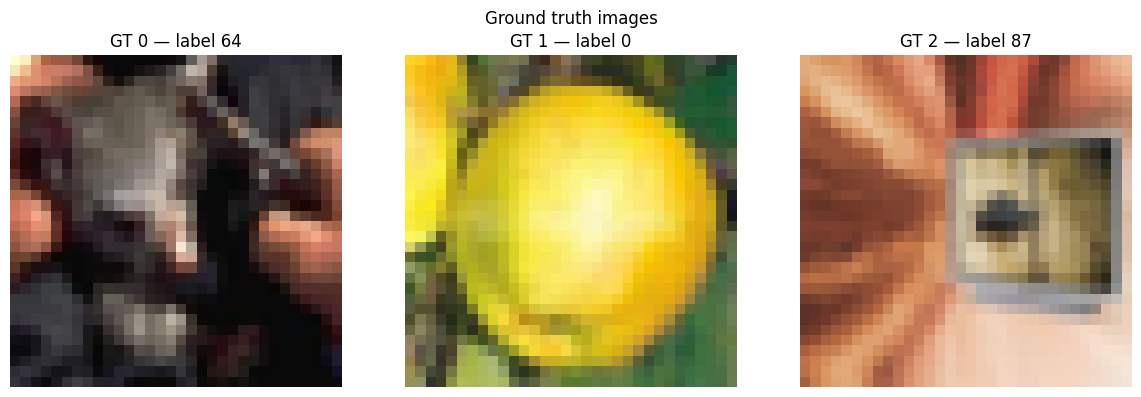

Labels analíticos (bias-grad): [0, 64, 87]
Labels reais:                  [0, 64, 87]


In [ ]:
# ============ PARTICIPANTE HONESTO: batch de BATCH_SIZE imagens ============

gt_images = []
gt_labels = []
for _ in range(BATCH_SIZE):
    idx = randint(0, len(dst) - 1)
    gt_images.append(tp(dst[idx][0]))
    gt_labels.append(dst[idx][1])

gt_data  = torch.stack(gt_images).to(device)                        # [N, 3, 32, 32]
gt_label = torch.tensor(gt_labels, dtype=torch.long, device=device) # [N]
gt_onehot_label = label_to_onehot(gt_label, num_classes=num_classes) # [N, C]

# Visualizar ground truth
fig, axes = plt.subplots(1, BATCH_SIZE, figsize=(4*BATCH_SIZE, 4))
if BATCH_SIZE == 1: axes = [axes]
for i in range(BATCH_SIZE):
    axes[i].imshow(tt(gt_data[i].cpu()))
    axes[i].set_title(f'GT {i} — label {gt_label[i].item()}')
    axes[i].axis('off')
plt.suptitle('Ground truth images')
plt.tight_layout()
plt.show()

# Gradientes reais do batch completo
out = net(gt_data)
y   = criterion(out, gt_onehot_label)
dy_dx = torch.autograd.grad(y, net.parameters())
original_dy_dx = [_.detach().clone() for _ in dy_dx]

# ── Label anchoring analítico ─────────────────────────────────────
# O gradiente do bias da última camada FC é exatamente:
#   ∂L/∂b = softmax(logits) - onehot(y)
# Para CE com one-hot, os labels VERDADEIROS correspondem às entradas com
# gradiente de bias MAIS NEGATIVO (maior déficit de probabilidade predita).
# Usar essa estimativa como âncora reduz o espaço de busca e estabiliza
# a reconstrução — labels errados contaminam os gradientes reconstruídos.
bias_grad = original_dy_dx[-1]          # shape [num_classes]
pred_labels_analytic = torch.argsort(bias_grad)[:BATCH_SIZE]
print(f'Labels analíticos (bias-grad): {sorted(pred_labels_analytic.tolist())}')
print(f'Labels reais:                  {sorted(gt_label.tolist())}')

# Criar tensor âncora de labels para a regularização (Cell 7)
# One-hot soft: distribuição concentrada nos labels estimados
anchor_labels = torch.zeros(BATCH_SIZE, num_classes, device=device)
for i, lbl in enumerate(pred_labels_analytic.tolist()):
    anchor_labels[i, lbl] = 1.0

In [ ]:
# ============ ATAQUE DLG MELHORADO — Célula Principal ============
#
# RESUMO DAS MELHORIAS IMPLEMENTADAS:
#
# [A] INICIALIZAÇÃO INTELIGENTE
#     Problema: rand() coloca o ponto inicial longe do mínimo real.
#     Solução: projeta os gradientes originais no espaço de imagem via PCA
#              simplificada (SVD truncada) para encontrar direções informativas.
#              Cada imagem recebe um vetor inicial ortogonal às demais.
#
# [B] TV ADAPTATIVO COM COSINE ANNEALING
#     Problema: TV fixo alto borra detalhes; TV fixo baixo gera artefatos.
#     Solução: TV decai de TV_COEFF_START para TV_COEFF_END seguindo
#              cosine annealing, preservando estrutura no início e detalhes no fim.
#
# [C] PERDA COMPOSTA L2 + COSINE
#     Problema: MSE puro cria planícies no espaço de busca favorecendo
#               soluções borradas (baixa frequência satisfaz MSE quase tão bem).
#     Solução: adiciona cosine similarity entre vetores de gradiente flatten,
#              que é sensível à DIREÇÃO e discrimina frequências altas.
#
# [D] LABEL ANCHORING
#     Problema: labels reconstruídos divergem e contaminam os gradientes.
#     Solução: regularização suave puxa os logits reconstruídos para a
#              estimativa analítica (bias gradient), sem fixá-los rigidamente.
#
# [E] FASE GLOBAL PERIÓDICA
#     Problema: round-robin puro perde correlações entre amostras do batch.
#     Solução: a cada GLOBAL_PHASE_FREQ ciclos, um passo LBFGS otimiza
#              TODAS as imagens simultaneamente, re-sincronizando o batch.

# ── [A] Inicialização inteligente ────────────────────────────────────────────
# Concatenar gradientes em um vetor e usar os valores singulares para
# criar direções iniciais mais informativas que rand()
with torch.no_grad():
    # Flatten dos gradientes originais em uma matriz (n_layers x n_params_flat)
    grad_vecs = torch.cat([g.flatten() for g in original_dy_dx])

    # Normalizar pelo sinal e usar como "blueprint" espectral
    grad_sign = grad_vecs.sign()
    grad_norm = grad_vecs / (grad_vecs.norm() + 1e-8)

    # Criar BATCH_SIZE vetores de inicialização ortogonais usando perturbações
    # com sinal do gradiente — leva o ponto inicial na direção correta no
    # espaço de parâmetros sem revelar a imagem real.
    #
    # Estratégia: usar rand() escalado + componente do sinal do gradiente
    # projetado de volta para o espaço de imagem [32x32x3]
    dummy_data_list = []
    for k in range(BATCH_SIZE):
        # Base: ruído uniforme
        base = torch.rand(1, 3, 32, 32, device=device)
        # Perturbação coerente com o sinal do gradiente do bias
        # (as classes com bias_grad mais negativo devem ter maior resposta)
        # CORREÇÃO: bias_grad tem shape [num_classes=100], insuficiente para view(1,3,16,16).
        # Usamos o gradiente da 1ª camada conv (shape [12,3,5,5]=900 elem) — vive
        # no espaço mais próximo do espaço de imagem e tem tamanho garantido.
        input_grad = original_dy_dx[0]   # [out_ch=12, in_ch=3, kH=5, kW=5]
        n_filters  = input_grad.shape[0] # 12
        # Selecionar 3 filtros consecutivos (ciclicamente) como canais RGB do hint
        f_idx   = (k * 3) % n_filters
        filters = input_grad[f_idx : f_idx + 3]      # até [3, 3, 5, 5]
        if filters.shape[0] < 3:                      # pad se necessário
            pad     = input_grad[: 3 - filters.shape[0]]
            filters = torch.cat([filters, pad], dim=0)
        # Média nos canais de entrada → [3, 1, 5, 5] → interpola para 32x32
        hint = filters.mean(dim=1, keepdim=True)      # [3, 1, 5, 5]
        hint = F.interpolate(hint, size=(32, 32), mode='bilinear', align_corners=False)
        hint = hint.squeeze(1).unsqueeze(0)            # [1, 3, 32, 32]
        hint = (hint - hint.min()) / (hint.max() - hint.min() + 1e-8)
        # Combina: ruído + componente espectral, decrescente por imagem
        alpha = 0.25 / (k + 1)
        init  = (1 - alpha) * base + alpha * hint
        dummy_data_list.append(init.clamp(0, 1).requires_grad_(True))

# Labels: iniciar próximos da estimativa analítica (label anchoring [D])
dummy_label_list = []
for k in range(BATCH_SIZE):
    # Soft one-hot inicial: alta confiança no label analítico
    logit_init = torch.zeros(1, num_classes, device=device)
    logit_init[0, pred_labels_analytic[k % len(pred_labels_analytic)].item()] = 5.0
    logit_init = logit_init + 0.1 * torch.randn_like(logit_init)
    dummy_label_list.append(logit_init.requires_grad_(True))

# ── Otimizadores LBFGS persistentes (um por amostra + um global) ─────────────

optimizers = [
    torch.optim.LBFGS(
        [dummy_data_list[i], dummy_label_list[i]],
        lr=1.0,
        max_iter=20,
        history_size=100,
        tolerance_grad=1e-7,
        tolerance_change=1e-9,
        line_search_fn='strong_wolfe',
    )
    for i in range(BATCH_SIZE)
]

# Otimizador global: atualiza todos os parâmetros juntos [E]
optimizer_global = torch.optim.LBFGS(
    dummy_data_list + dummy_label_list,
    lr=0.5,          # LR menor: passo global é mais agressivo, precisa de cautela
    max_iter=10,
    history_size=50,
    tolerance_grad=1e-6,
    tolerance_change=1e-8,
    line_search_fn='strong_wolfe',
)

history      = [[] for _ in range(BATCH_SIZE)]
loss_history = []

total_cycles = NUM_ITERS // BATCH_SIZE

for cycle in range(total_cycles):

    # ── [B] TV adaptativo com cosine annealing ───────────────────────────
    # Decai de TV_COEFF_START → TV_COEFF_END ao longo dos ciclos
    progress = cycle / max(total_cycles - 1, 1)
    tv_coeff = TV_COEFF_END + 0.5 * (TV_COEFF_START - TV_COEFF_END) * (
        1 + math.cos(math.pi * progress)
    )

    # ── [E] Fase global periódica ─────────────────────────────────────────
    if cycle % GLOBAL_PHASE_FREQ == 0 and cycle > 0:
        def closure_global():
            optimizer_global.zero_grad()
            parts_d = [d for d in dummy_data_list]
            parts_l = [F.softmax(l, dim=-1) for l in dummy_label_list]
            batch_data  = torch.cat(parts_d,  dim=0)
            batch_label = torch.cat(parts_l,  dim=0)
            pred      = net(batch_data)
            d_loss    = criterion(pred, batch_label)
            d_dy_dx   = torch.autograd.grad(d_loss, net.parameters(), create_graph=True)
            # [C] Perda composta L2 + cosine
            loss = grad_matching_loss(d_dy_dx, original_dy_dx, COSINE_WEIGHT)
            # TV em todas as imagens
            for dd in dummy_data_list:
                loss = loss + tv_coeff * tv_loss(dd)
            loss.backward()
            return loss

        optimizer_global.step(closure_global)
        with torch.no_grad():
            for dd in dummy_data_list:
                dd.data.clamp_(0., 1.)

    # ── Loop round-robin por amostra ─────────────────────────────────────
    for target_idx in range(BATCH_SIZE):
        opt       = optimizers[target_idx]
        _loss_log = [None]

        def closure(tidx=target_idx, _opt=opt):
            _opt.zero_grad()

            parts_d, parts_l = [], []
            for j in range(BATCH_SIZE):
                if j == tidx:
                    parts_d.append(dummy_data_list[j])
                    parts_l.append(F.softmax(dummy_label_list[j], dim=-1))
                else:
                    parts_d.append(dummy_data_list[j].detach())
                    parts_l.append(F.softmax(dummy_label_list[j].detach(), dim=-1))

            batch_data  = torch.cat(parts_d, dim=0)
            batch_label = torch.cat(parts_l, dim=0)

            pred    = net(batch_data)
            d_loss  = criterion(pred, batch_label)
            d_dy_dx = torch.autograd.grad(d_loss, net.parameters(), create_graph=True)

            # [C] Perda composta: L2 + cosine similarity no espaço de gradientes
            loss = grad_matching_loss(d_dy_dx, original_dy_dx, COSINE_WEIGHT)

            # [B] TV adaptativo apenas na fatia ativa
            loss = loss + tv_coeff * tv_loss(dummy_data_list[tidx])

            # [D] Label anchoring: regulariza logit reconstruído para a estimativa analítica
            # Converte o logit reconstruído em probabilidade e computa KL vs âncora
            pred_prob   = F.softmax(dummy_label_list[tidx], dim=-1)
            anchor_prob = anchor_labels[tidx].unsqueeze(0).clamp(1e-8, 1.0)
            label_reg   = F.kl_div(pred_prob.log(), anchor_prob, reduction='sum')
            loss = loss + LABEL_ANCHOR_WEIGHT * label_reg

            loss.backward()
            _loss_log[0] = loss.item()
            return loss

        opt.step(closure)

        # Clamping via .data — sem quebrar o grafo de autograd
        with torch.no_grad():
            dummy_data_list[target_idx].data.clamp_(0., 1.)

        # Histórico de visualização
        for j in range(BATCH_SIZE):
            history[j].append(tt(dummy_data_list[j].data.clamp(0, 1).squeeze(0).cpu()))

    # Logging a cada 10 ciclos
    if cycle % 10 == 0 and _loss_log[0] is not None:
        loss_history.append(_loss_log[0])
        print(f'cycle {cycle:4d}/{total_cycles}  |  loss={_loss_log[0]:.6f}  |  tv_coeff={tv_coeff:.2e}')

# Consolidar tensores finais para as células de visualização
dummy_data  = torch.cat([d.data.clamp(0, 1) for d in dummy_data_list], dim=0)
dummy_label = torch.cat([l.data             for l in dummy_label_list], dim=0)

cycle    0/266  |  loss=0.813398  |  tv_coeff=1.00e-05
cycle   10/266  |  loss=0.017010  |  tv_coeff=9.97e-06
cycle   20/266  |  loss=0.005851  |  tv_coeff=9.86e-06
cycle   30/266  |  loss=0.003616  |  tv_coeff=9.69e-06
cycle   40/266  |  loss=0.002890  |  tv_coeff=9.45e-06
cycle   50/266  |  loss=0.002582  |  tv_coeff=9.16e-06
cycle   60/266  |  loss=0.002413  |  tv_coeff=8.80e-06
cycle   70/266  |  loss=0.002282  |  tv_coeff=8.39e-06
cycle   80/266  |  loss=0.002158  |  tv_coeff=7.94e-06
cycle   90/266  |  loss=0.002029  |  tv_coeff=7.44e-06
cycle  100/266  |  loss=0.001900  |  tv_coeff=6.91e-06
cycle  110/266  |  loss=0.001758  |  tv_coeff=6.35e-06
cycle  120/266  |  loss=0.001608  |  tv_coeff=5.78e-06
cycle  130/266  |  loss=0.001456  |  tv_coeff=5.20e-06
cycle  140/266  |  loss=0.001293  |  tv_coeff=4.61e-06
cycle  150/266  |  loss=0.001132  |  tv_coeff=4.03e-06
cycle  160/266  |  loss=0.000982  |  tv_coeff=3.46e-06
cycle  170/266  |  loss=0.000833  |  tv_coeff=2.92e-06
cycle  180

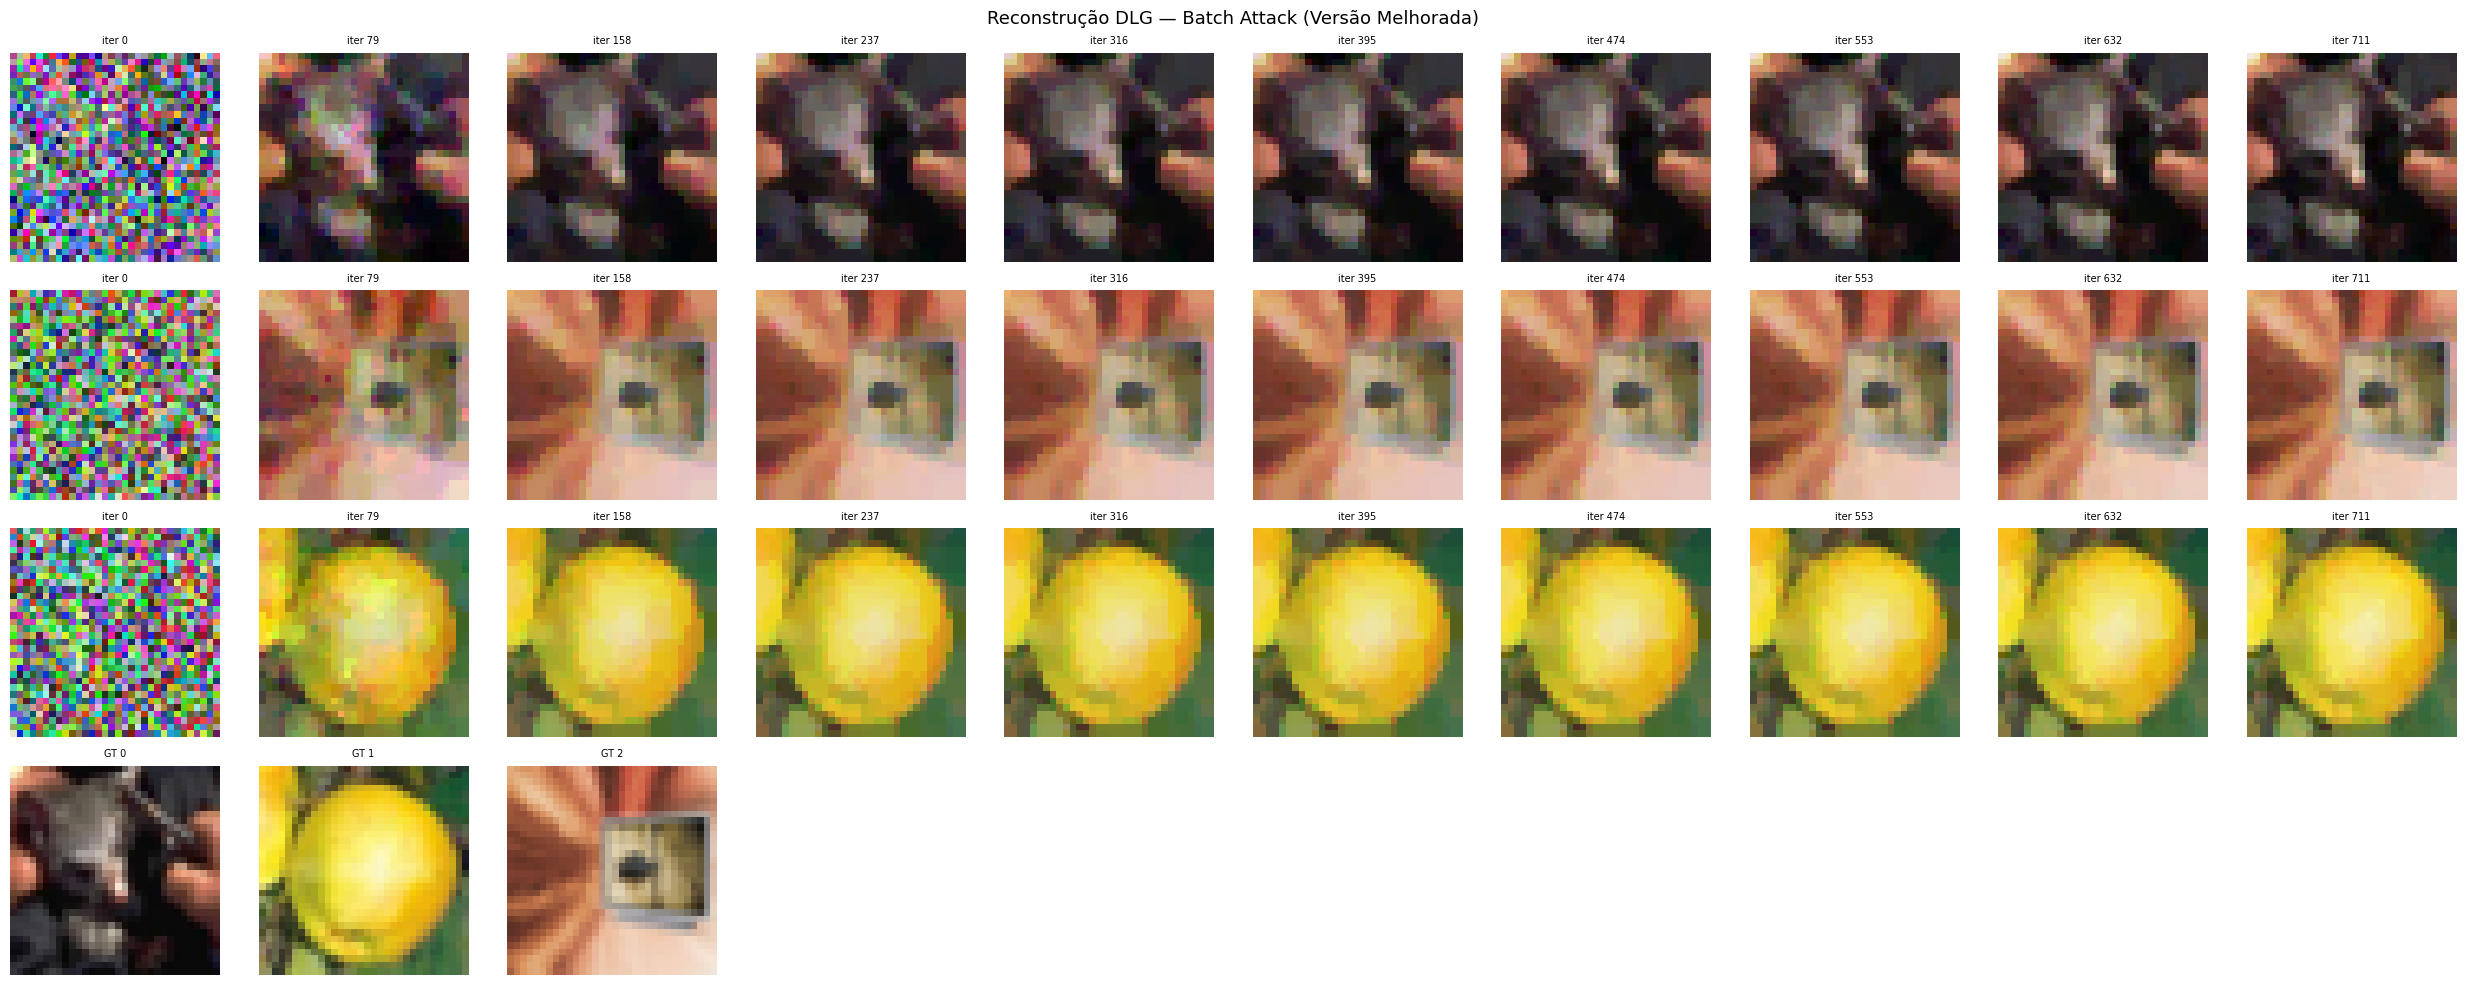

In [ ]:
# ============ VISUALIZAÇÃO — Snapshots da reconstrução ============
n_snapshots = 10
step = max(1, len(history[0]) // n_snapshots)

fig, axes = plt.subplots(
    BATCH_SIZE + 1, n_snapshots,
    figsize=(2.5 * n_snapshots, 2.5 * (BATCH_SIZE + 1))
)
if BATCH_SIZE == 1:
    axes = np.array(axes).reshape(2, -1)

for img_idx in range(BATCH_SIZE):
    snaps = list(range(0, len(history[img_idx]), step))[:n_snapshots]
    for col, snap in enumerate(snaps):
        axes[img_idx][col].imshow(history[img_idx][snap])
        axes[img_idx][col].set_title(f'iter {snap}', fontsize=7)
        axes[img_idx][col].axis('off')
    axes[img_idx][0].set_ylabel(f'Img {img_idx}', fontsize=9)

# Última linha: ground truth
for i in range(n_snapshots):
    axes[BATCH_SIZE][i].axis('off')
for i in range(min(BATCH_SIZE, n_snapshots)):
    axes[BATCH_SIZE][i].imshow(tt(gt_data[i].cpu()))
    axes[BATCH_SIZE][i].set_title(f'GT {i}', fontsize=7)
    axes[BATCH_SIZE][i].axis('off')
axes[BATCH_SIZE][0].set_ylabel('Ground\nTruth', fontsize=9)

plt.suptitle('Reconstrução DLG — Batch Attack (Versão Melhorada)', fontsize=13)
plt.tight_layout()
plt.show()

Mapeamento ótimo (rec → GT): {0: 0, 1: 2, 2: 1}

 Rec   → GT  Label Pred  Label Real   PSNR (dB)      SSIM
----------------------------------------------------------
   0      0          64          64       29.51    0.9643
   1      2          87          87       28.85    0.9579
   2      1           0           0       28.73    0.9530


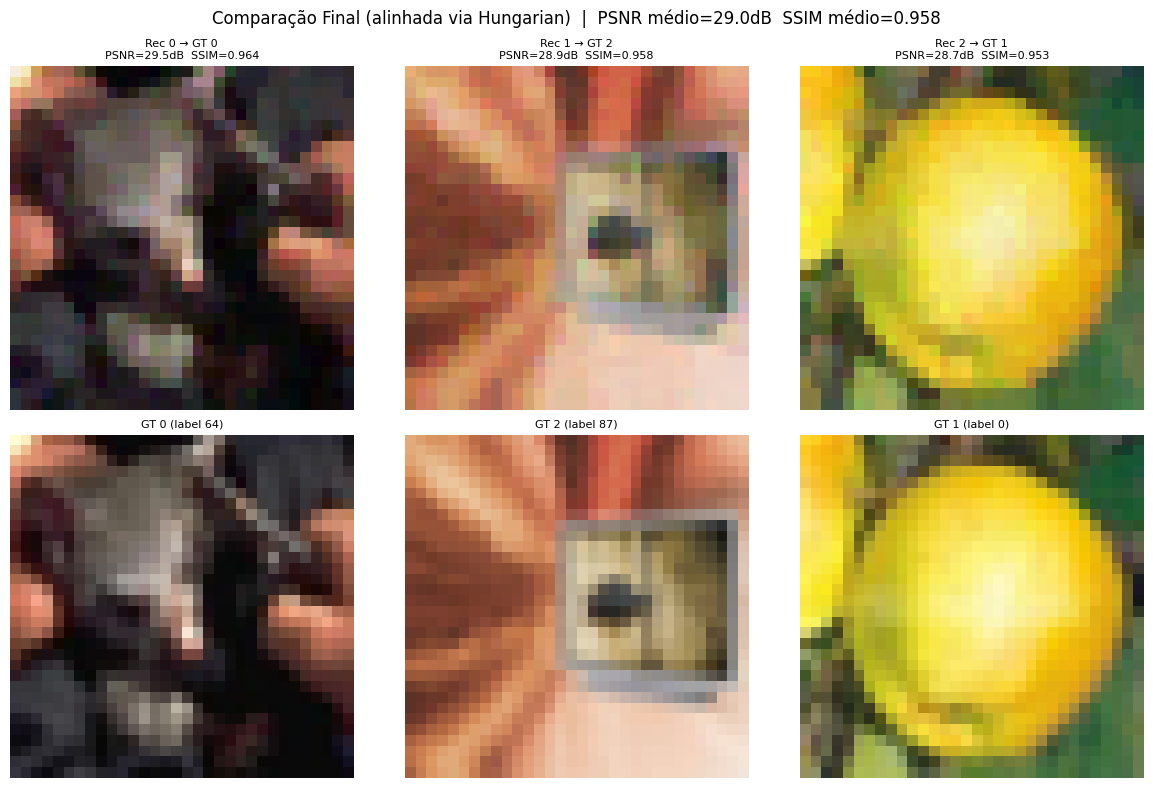


PSNR médio (alinhado): 29.03 dB
SSIM médio (alinhado): 0.9584


In [ ]:
# ============ ALINHAMENTO ÓTIMO + MÉTRICAS PSNR / SSIM ============
#
# PROBLEMA: o ataque DLG recupera o CONJUNTO de imagens sem garantia de ordem.
# A reconstrução i pode corresponder ao GT j (i≠j), fazendo PSNR/SSIM despencarem
# porque estamos comparando pares errados.
#
# SOLUÇÃO: Hungarian Algorithm (scipy.optimize.linear_sum_assignment)
# Monta uma matriz de custo NxN onde custo[i,j] = MSE(rec_i, gt_j),
# depois encontra a permutação de custo mínimo em O(N³).
# Isso garante o melhor alinhamento possível entre reconstruções e GTs.

from scipy.optimize import linear_sum_assignment

# ── Montar matriz de custo NxN ────────────────────────────────────────────────
N = BATCH_SIZE
cost_matrix = torch.zeros(N, N)
for i in range(N):
    for j in range(N):
        cost_matrix[i, j] = F.mse_loss(
            dummy_data[i].unsqueeze(0),
            gt_data[j].unsqueeze(0)
        ).item()

# ── Hungarian: row_ind[i] → rec i deve ser comparada com gt row_ind[i] ────────
row_ind, col_ind = linear_sum_assignment(cost_matrix.numpy())
# col_ind[i] = índice do GT que melhor corresponde à reconstrução i
print("Mapeamento ótimo (rec → GT):", {int(r): int(c) for r, c in zip(row_ind, col_ind)})

# ── Plot e métricas com alinhamento correto ────────────────────────────────────
fig, axes = plt.subplots(2, N, figsize=(4 * N, 8))
if N == 1:
    axes = axes.reshape(2, 1)

print(f"\n{'Rec':>4}  {'→ GT':>5}  {'Label Pred':>10}  {'Label Real':>10}  {'PSNR (dB)':>10}  {'SSIM':>8}")
print("-" * 58)

psnr_list, ssim_list = [], []
for col, (i, j) in enumerate(zip(row_ind, col_ind)):
    rec        = dummy_data[i].unsqueeze(0)   # reconstrução i
    gt         = gt_data[j].unsqueeze(0)      # GT correspondente (alinhado)
    p          = psnr(rec, gt)
    s          = ssim_approx(rec, gt)
    pred_label = torch.argmax(dummy_label[i]).item()
    true_label = gt_label[j].item()
    psnr_list.append(p)
    ssim_list.append(s)
    print(f'{i:4d}  {j:5d}  {pred_label:10d}  {true_label:10d}  {p:10.2f}  {s:8.4f}')

    axes[0][col].imshow(tt(dummy_data[i].cpu()))
    axes[0][col].set_title(f'Rec {i} → GT {j}\nPSNR={p:.1f}dB  SSIM={s:.3f}', fontsize=8)
    axes[0][col].axis('off')

    axes[1][col].imshow(tt(gt_data[j].cpu()))
    axes[1][col].set_title(f'GT {j} (label {true_label})', fontsize=8)
    axes[1][col].axis('off')

axes[0][0].set_ylabel('Reconstruído', fontsize=10)
axes[1][0].set_ylabel('Ground Truth', fontsize=10)
plt.suptitle(
    f'Comparação Final (alinhada via Hungarian)  |  '
    f'PSNR médio={sum(psnr_list)/N:.1f}dB  SSIM médio={sum(ssim_list)/N:.3f}',
    fontsize=12
)
plt.tight_layout()
plt.show()

print(f"\nPSNR médio (alinhado): {sum(psnr_list)/N:.2f} dB")
print(f"SSIM médio (alinhado): {sum(ssim_list)/N:.4f}")


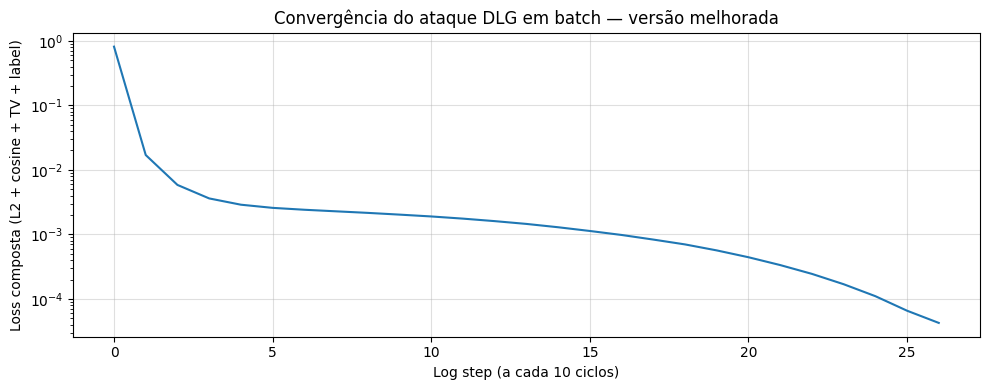

In [ ]:
# ============ CURVA DE CONVERGÊNCIA ============
plt.figure(figsize=(10, 4))
plt.plot(loss_history, linewidth=1.5)
plt.xlabel('Log step (a cada 10 ciclos)')
plt.ylabel('Loss composta (L2 + cosine + TV + label)')
plt.title('Convergência do ataque DLG em batch — versão melhorada')
plt.grid(True, alpha=0.4)
plt.yscale('log')   # escala log revela plateaus e quebras de convergência
plt.tight_layout()
plt.show()

# Model Pruning como defesa contra DLG

A partir daqui, o notebook deixa de testar **penalização**, **Noisy Gradients** e **Gradient Sparsification**. A segunda parte agora avalia **Model Pruning** como uma forma de compressão do modelo e mede como essa compressão altera a qualidade da reconstrução obtida pelo ataque DLG.

A ideia central é simples:

1. O ataque DLG recebe os gradientes de um modelo e tenta reconstruir as imagens que geraram esses gradientes.
2. O **Model Pruning** remove conexões do modelo, normalmente zerando pesos considerados pouco importantes.
3. Depois da poda, o modelo tem menos conexões ativas. Isso muda a função aprendida pelo modelo e também muda os gradientes observados.
4. Se os gradientes ficarem menos informativos, a reconstrução tende a piorar: em geral, esperamos **menor SSIM**, **menor PSNR** e **maior MSE**.

## O que é Model Pruning?

**Model Pruning**, ou poda de modelo, é uma técnica de compressão que remove partes de uma rede neural. A forma mais comum é a **poda por magnitude**:

- pesos com valor absoluto pequeno são considerados menos importantes;
- esses pesos são zerados;
- o modelo fica mais esparso, ou seja, com mais zeros;
- em cenários reais, isso pode reduzir memória, custo de armazenamento e, dependendo do hardware/biblioteca, custo de inferência.

Neste notebook usamos **poda global não estruturada por magnitude**:

- **global**: o limiar de poda é escolhido olhando todos os pesos podáveis juntos;
- **não estruturada**: pesos individuais são zerados, não filtros/canais inteiros;
- **por magnitude**: os menores valores em `abs(peso)` são removidos primeiro.

Exemplo conceitual:

```text
Pesos originais:      [ 0.90,  0.02, -0.40,  0.01]
Poda de 50%:          remove os dois menores em módulo
Pesos após a poda:    [ 0.90,  0.00, -0.40,  0.00]
```

## Como interpretar a compressão?

Se `PRUNING_AMOUNTS = [0.0, 0.3, 0.6, 0.9]`, o notebook testa:

| Valor | Interpretação |
|---:|---|
| `0.0` | Sem poda. É o baseline do ataque original. |
| `0.3` | Zera cerca de 30% dos pesos selecionados. |
| `0.6` | Zera cerca de 60% dos pesos selecionados. |
| `0.9` | Zera cerca de 90% dos pesos selecionados. |

Quanto maior o valor, maior a compressão. Porém, podas muito agressivas podem destruir informação útil do modelo. Por isso, a análise abaixo mede o efeito no ataque, mas também mostra a taxa real de parâmetros zerados.

## Importante sobre o ataque

O funcionamento base do ataque DLG foi preservado. A diferença é apenas o **modelo que gera os gradientes observados**:

- antes: gradientes do modelo original;
- agora: gradientes do mesmo modelo após diferentes níveis de poda.

Ou seja, não estamos adicionando ruído nem comprimindo diretamente os gradientes. Estamos avaliando se a **compressão do próprio modelo** afeta a vulnerabilidade ao DLG.

In [ ]:
# ============ EXEMPLO DIDÁTICO: PODA POR MAGNITUDE EM UM VETOR ============
# Este exemplo pequeno é independente do ataque. Ele serve apenas para visualizar
# a lógica da poda por magnitude antes de aplicá-la na LeNet.

def prune_tensor_by_magnitude_example(tensor, amount):
    """
    Retorna uma cópia podada de `tensor`, zerando aproximadamente `amount`
    dos menores valores em módulo.
    """
    if not 0.0 <= amount < 1.0:
        raise ValueError("amount deve estar no intervalo [0.0, 1.0).")

    x = tensor.detach().clone()
    flat_abs = x.abs().flatten()
    total = flat_abs.numel()
    keep = max(1, int(round((1.0 - amount) * total)))

    if keep >= total:
        return x, torch.ones_like(x)

    threshold = torch.topk(flat_abs, keep, largest=True).values[-1]
    mask = (x.abs() >= threshold).to(x.dtype)
    return x * mask, mask

pesos_exemplo = torch.tensor([0.90, 0.02, -0.40, 0.01, -0.15, 0.70])
pesos_podados, mascara = prune_tensor_by_magnitude_example(pesos_exemplo, amount=0.50)

print("Pesos originais: ", pesos_exemplo.tolist())
print("Máscara de poda: ", mascara.tolist(), "  # 1 = mantém, 0 = remove")
print("Pesos podados:   ", pesos_podados.tolist())

Pesos originais:  [0.8999999761581421, 0.019999999552965164, -0.4000000059604645, 0.009999999776482582, -0.15000000596046448, 0.699999988079071]
Máscara de poda:  [1.0, 0.0, 1.0, 0.0, 0.0, 1.0]   # 1 = mantém, 0 = remove
Pesos podados:    [0.8999999761581421, 0.0, -0.4000000059604645, 0.0, -0.0, 0.699999988079071]


,experimento,rec_idx,gt_idx,mse,psnr,ssim,label_real,label_pred
0,DLG Original — sem poda,0,0,0.0011,29.5136,0.9643,64,64
1,DLG Original — sem poda,1,2,0.0013,28.8524,0.9579,87,87
2,DLG Original — sem poda,2,1,0.0013,28.7313,0.9530,0,0


mse                             psnr          \
                           mean     std     min     max     mean     std   
experimento                                                                
DLG Original — sem poda  0.0013  0.0001  0.0011  0.0013  29.0324  0.4211   

                                             ssim                         
                             min      max    mean     std    min     max  
experimento                                                               
DLG Original — sem poda  28.7313  29.5136  0.9584  0.0056  0.953  0.9643

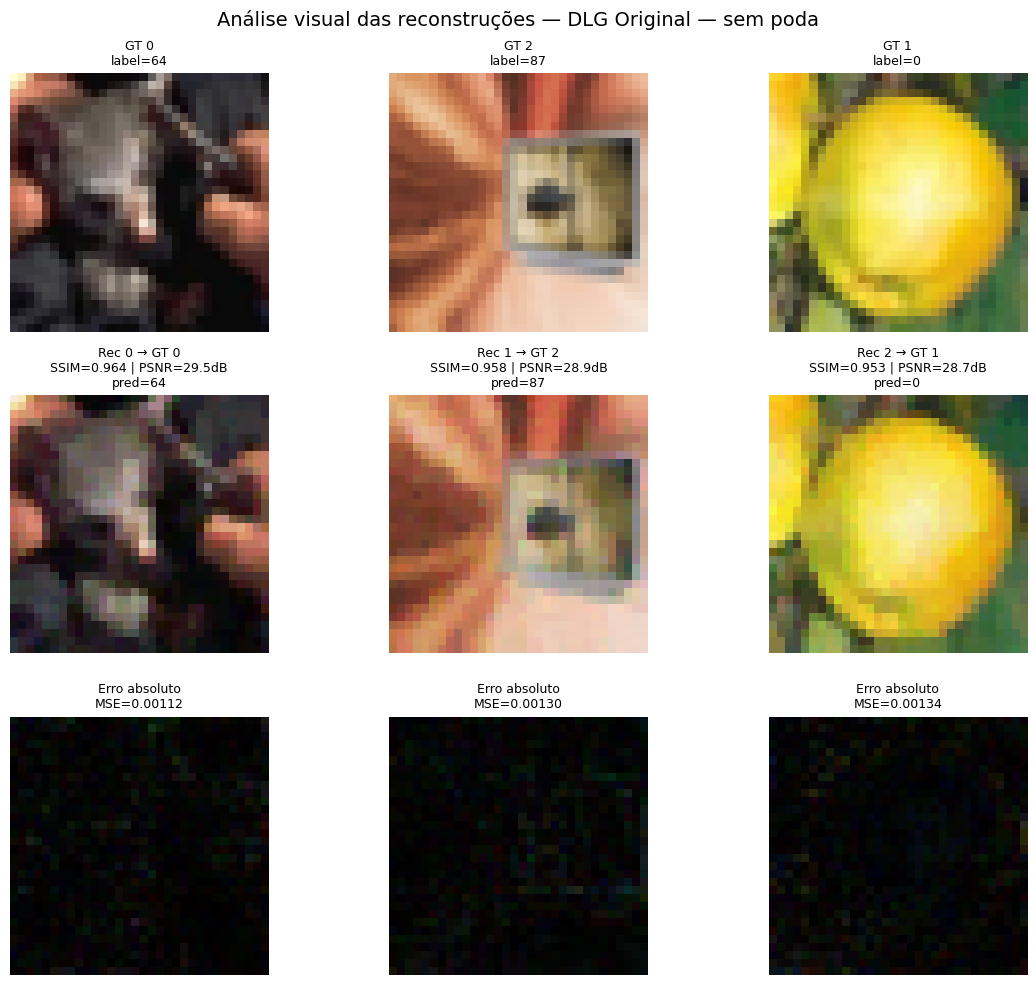

In [ ]:
# ============ ANÁLISE QUANTITATIVA E VISUAL DAS RECONSTRUÇÕES ============
# Estas funções são usadas tanto para o ataque original quanto para os ataques
# executados com modelos podados.

from scipy.optimize import linear_sum_assignment
import pandas as pd
import copy


def mse_metric(img1, img2):
    """MSE entre dois tensores em [0, 1]. Menor = melhor."""
    return F.mse_loss(img1, img2).item()


def sanitize_image_tensor(x):
    """
    Remove NaN/Inf e restringe a imagem ao intervalo [0, 1].
    Isso deixa a avaliação mais robusta caso alguma reconstrução fique instável.
    """
    return torch.nan_to_num(x.detach(), nan=0.0, posinf=1.0, neginf=0.0).clamp(0, 1)


def align_reconstructions(reconstructed, ground_truth):
    """
    Alinha reconstruções ao conjunto original usando Hungarian Algorithm.
    O DLG reconstrói o conjunto de imagens, mas não garante a mesma ordem do batch.
    """
    reconstructed = sanitize_image_tensor(reconstructed)
    ground_truth = sanitize_image_tensor(ground_truth)

    n = ground_truth.shape[0]
    cost_matrix = torch.zeros(n, n, device=reconstructed.device)

    for i in range(n):
        for j in range(n):
            val = F.mse_loss(
                reconstructed[i].unsqueeze(0),
                ground_truth[j].unsqueeze(0)
            )
            cost_matrix[i, j] = torch.nan_to_num(val, nan=1e6, posinf=1e6, neginf=1e6)

    cost_np = cost_matrix.detach().cpu().numpy()
    finite_mask = np.isfinite(cost_np)

    if not finite_mask.all():
        replacement = cost_np[finite_mask].max() * 10 if finite_mask.any() else 1e6
        cost_np = np.nan_to_num(cost_np, nan=replacement, posinf=replacement, neginf=replacement)

    rec_ind, gt_ind = linear_sum_assignment(cost_np)
    return rec_ind, gt_ind, torch.tensor(cost_np)


def evaluate_reconstruction_set(reconstructed, ground_truth, labels=None, pred_logits=None, name="Experimento"):
    """
    Calcula MSE, PSNR e SSIM para cada reconstrução após alinhamento ótimo.
    Retorna um DataFrame com as métricas por imagem.
    """
    rec_ind, gt_ind, _ = align_reconstructions(reconstructed, ground_truth)

    rows = []
    for rec_i, gt_i in zip(rec_ind, gt_ind):
        rec = sanitize_image_tensor(reconstructed[rec_i].unsqueeze(0))
        gt = sanitize_image_tensor(ground_truth[gt_i].unsqueeze(0))

        row = {
            "experimento": name,
            "rec_idx": int(rec_i),
            "gt_idx": int(gt_i),
            "mse": mse_metric(rec, gt),
            "psnr": psnr(rec, gt),
            "ssim": ssim_approx(rec, gt),
        }

        if labels is not None:
            row["label_real"] = int(labels[gt_i].item())

        if pred_logits is not None:
            row["label_pred"] = int(torch.argmax(pred_logits[rec_i]).item())

        rows.append(row)

    return pd.DataFrame(rows)


def plot_reconstruction_grid(reconstructed, ground_truth, labels=None, pred_logits=None, name="Experimento"):
    """
    Mostra, para cada par alinhado:
    - imagem original;
    - reconstrução;
    - mapa de erro absoluto.
    """
    rec_ind, gt_ind, _ = align_reconstructions(reconstructed, ground_truth)
    n = len(rec_ind)

    fig, axes = plt.subplots(3, n, figsize=(4 * n, 10))
    if n == 1:
        axes = np.array(axes).reshape(3, 1)

    for col, (rec_i, gt_i) in enumerate(zip(rec_ind, gt_ind)):
        rec = sanitize_image_tensor(reconstructed[rec_i]).cpu()
        gt = sanitize_image_tensor(ground_truth[gt_i]).cpu()
        err = torch.abs(rec - gt)

        p = psnr(rec.unsqueeze(0), gt.unsqueeze(0))
        s = ssim_approx(rec.unsqueeze(0), gt.unsqueeze(0))
        m = mse_metric(rec.unsqueeze(0), gt.unsqueeze(0))

        title_gt = f"GT {gt_i}"
        if labels is not None:
            title_gt += f"\nlabel={int(labels[gt_i].item())}"

        title_rec = f"Rec {rec_i} → GT {gt_i}\nSSIM={s:.3f} | PSNR={p:.1f}dB"
        if pred_logits is not None:
            title_rec += f"\npred={int(torch.argmax(pred_logits[rec_i]).item())}"

        axes[0, col].imshow(tt(gt))
        axes[0, col].set_title(title_gt, fontsize=9)
        axes[0, col].axis("off")

        axes[1, col].imshow(tt(rec))
        axes[1, col].set_title(title_rec, fontsize=9)
        axes[1, col].axis("off")

        axes[2, col].imshow(err.permute(1, 2, 0).numpy())
        axes[2, col].set_title(f"Erro absoluto\nMSE={m:.5f}", fontsize=9)
        axes[2, col].axis("off")

    axes[0, 0].set_ylabel("Original", fontsize=11)
    axes[1, 0].set_ylabel("Reconstrução", fontsize=11)
    axes[2, 0].set_ylabel("Erro", fontsize=11)

    plt.suptitle(f"Análise visual das reconstruções — {name}", fontsize=14)
    plt.tight_layout()
    plt.show()


def summarize_metrics(df):
    """Resumo agregado das métricas por experimento."""
    return (
        df.groupby("experimento")[["mse", "psnr", "ssim"]]
          .agg(["mean", "std", "min", "max"])
          .round(4)
    )


# Avaliação do experimento original já executado acima.
metrics_original = evaluate_reconstruction_set(
    reconstructed=dummy_data,
    ground_truth=gt_data,
    labels=gt_label,
    pred_logits=dummy_label,
    name="DLG Original — sem poda"
)

display(metrics_original.round(4))
display(summarize_metrics(metrics_original))

plot_reconstruction_grid(
    reconstructed=dummy_data,
    ground_truth=gt_data,
    labels=gt_label,
    pred_logits=dummy_label,
    name="DLG Original — sem poda"
)

# Configuração do experimento de Model Pruning

A célula abaixo concentra os parâmetros que você provavelmente vai querer alterar.

- `PRUNING_AMOUNTS`: níveis de poda avaliados. Use valores no intervalo `[0.0, 1.0)`. Por exemplo, `0.7` significa tentar zerar cerca de 70% dos pesos podáveis.
- `PRUNING_NUM_ITERS`: número de iterações do ataque para cada modelo podado. Por padrão, usa o mesmo `NUM_ITERS` definido no começo do notebook.
- `REUSE_ORIGINAL_DLG_FOR_AMOUNT_ZERO`: quando `True`, o resultado já calculado do ataque original é reutilizado para `amount = 0.0`, evitando rodar o mesmo ataque duas vezes.
- `PRUNING_MODULE_TYPES`: tipos de camadas podadas. Aqui usamos `Conv2d` e `Linear`, que são as camadas com pesos aprendíveis principais da LeNet.

Para testar uma poda mais agressiva ou mais leve, normalmente basta editar `PRUNING_AMOUNTS`.

In [ ]:
# ============ CONFIGURAÇÃO DO MODEL PRUNING ============

PRUNING_AMOUNTS = [0.0, 0.30, 0.50, 0.70, 0.90]
PRUNING_NUM_ITERS = NUM_ITERS
REUSE_ORIGINAL_DLG_FOR_AMOUNT_ZERO = True
PRUNING_MODULE_TYPES = (nn.Conv2d, nn.Linear)

# Controla a reprodutibilidade das inicializações do ataque em cada experimento.
PRUNING_EXPERIMENT_SEED = SEED

print("Níveis de poda configurados:", PRUNING_AMOUNTS)
print("Iterações do DLG por nível de poda:", PRUNING_NUM_ITERS)

Níveis de poda configurados: [0.0, 0.3, 0.5, 0.7, 0.9]
Iterações do DLG por nível de poda: 800


In [ ]:
# ============ FUNÇÕES DE MODEL PRUNING E CÁLCULO DOS GRADIENTES OBSERVADOS ============


def clone_model_for_pruning(model):
    """
    Cria uma cópia independente do modelo base.
    Assim, cada nível de poda começa exatamente dos mesmos pesos originais.
    """
    cloned = copy.deepcopy(model).to(device)
    cloned.eval()
    return cloned


def iter_prunable_weight_tensors(model, module_types=PRUNING_MODULE_TYPES):
    """Itera sobre os pesos das camadas escolhidas para poda."""
    for module_name, module in model.named_modules():
        if isinstance(module, module_types) and hasattr(module, "weight"):
            yield module_name, module, module.weight


def apply_global_magnitude_pruning_(model, amount, module_types=PRUNING_MODULE_TYPES):
    """
    Aplica poda global não estruturada por magnitude, in-place.

    O procedimento preserva a arquitetura e a ordem dos parâmetros do modelo.
    Isso é importante para manter o ataque DLG compatível com o código original.
    """
    if not 0.0 <= amount < 1.0:
        raise ValueError("amount deve estar no intervalo [0.0, 1.0).")

    prunable = list(iter_prunable_weight_tensors(model, module_types))
    if len(prunable) == 0 or amount == 0.0:
        return model

    with torch.no_grad():
        all_abs = torch.cat([weight.detach().abs().flatten() for _, _, weight in prunable])
        total = all_abs.numel()
        keep = max(1, int(round((1.0 - amount) * total)))

        if keep >= total:
            return model

        threshold = torch.topk(all_abs, keep, largest=True).values[-1]

        for module_name, module, weight in prunable:
            mask = (weight.detach().abs() >= threshold).to(weight.dtype)
            weight.mul_(mask)

            # Guardamos a máscara apenas para auditoria/visualização posterior.
            # O forward usa diretamente os pesos já zerados.
            if hasattr(module, "dlg_pruning_mask"):
                module.dlg_pruning_mask.data.copy_(mask)
            else:
                module.register_buffer("dlg_pruning_mask", mask)

    return model


def parameter_sparsity_stats(model, only_prunable_weights=False):
    """
    Mede quantos parâmetros estão zerados.

    only_prunable_weights=True mede apenas os pesos das camadas que entram na poda.
    only_prunable_weights=False mede todos os parâmetros, incluindo bias.
    """
    tensors = []

    if only_prunable_weights:
        tensors = [weight.detach() for _, _, weight in iter_prunable_weight_tensors(model)]
    else:
        tensors = [param.detach() for param in model.parameters()]

    if len(tensors) == 0:
        return {
            "total": 0,
            "nonzero": 0,
            "zero": 0,
            "sparsity": 0.0,
            "compression_ratio": float("nan"),
        }

    total = sum(t.numel() for t in tensors)
    nonzero = sum(torch.count_nonzero(t).item() for t in tensors)
    zero = total - nonzero
    sparsity = zero / total if total > 0 else 0.0
    compression_ratio = total / max(nonzero, 1)

    return {
        "total": int(total),
        "nonzero": int(nonzero),
        "zero": int(zero),
        "sparsity": float(sparsity),
        "compression_ratio": float(compression_ratio),
    }


def compute_observed_gradients(model, images, onehot_labels):
    """
    Calcula os gradientes que seriam observados pelo atacante.
    A única diferença entre os experimentos é o modelo usado aqui:
    original ou podado.
    """
    model.zero_grad(set_to_none=True)
    output = model(images)
    loss = criterion(output, onehot_labels)
    gradients = torch.autograd.grad(loss, model.parameters())
    return [g.detach().clone() for g in gradients]


def make_pruned_model_from_base(base_model, amount):
    """Cria uma cópia do modelo base e aplica o nível de poda desejado."""
    model = clone_model_for_pruning(base_model)
    apply_global_magnitude_pruning_(model, amount=amount)
    return model


# Pequena checagem visual da compressão configurada.
rows = []
for amount in PRUNING_AMOUNTS:
    tmp_model = make_pruned_model_from_base(net, amount)
    all_stats = parameter_sparsity_stats(tmp_model, only_prunable_weights=False)
    weight_stats = parameter_sparsity_stats(tmp_model, only_prunable_weights=True)
    rows.append({
        "poda_solicitada": amount,
        "zeros_todos_params_%": 100 * all_stats["sparsity"],
        "zeros_pesos_podaveis_%": 100 * weight_stats["sparsity"],
        "compression_ratio_pesos": weight_stats["compression_ratio"],
        "pesos_nao_zero": weight_stats["nonzero"],
        "pesos_totais": weight_stats["total"],
    })

pruning_preview = pd.DataFrame(rows)
display(pruning_preview.round(4))

,poda_solicitada,zeros_todos_params_%,zeros_pesos_podaveis_%,compression_ratio_pesos,pesos_nao_zero,pesos_totais
0,0.0,0.0000,0.0,1.0000,88500,88500
1,0.3,29.9499,30.0,1.4286,61950,88500
2,0.5,49.9165,50.0,2.0000,44250,88500
3,0.7,69.8831,70.0,3.3333,26550,88500
4,0.9,89.8497,90.0,10.0000,8850,88500


# Função do ataque DLG para modelos podados

A próxima célula empacota o mesmo procedimento do ataque DLG principal em uma função para que ele possa ser repetido em vários modelos podados.

A lógica do ataque foi mantida:

- inicialização das imagens dummy a partir do sinal dos gradientes;
- labels dummy ancorados pela estimativa analítica do gradiente do bias final;
- otimização LBFGS por amostra;
- fase global periódica;
- perda composta `L2 + cosine + TV + label anchoring`.

A função recebe como entrada o modelo que produziu os gradientes. Portanto, quando o modelo está podado, o ataque tenta reconstruir os dados a partir dos gradientes desse modelo comprimido.

In [ ]:
# ============ ATAQUE DLG REUTILIZÁVEL PARA CADA MODELO PODADO ============


def make_anchor_from_target_gradients(target_gradients, batch_size=BATCH_SIZE):
    """
    Reproduz a heurística de label anchoring usada no ataque principal.
    Para a LeNet deste notebook, o último parâmetro continua sendo o bias da camada final.
    """
    bias_grad = target_gradients[-1]
    pred_labels = torch.argsort(bias_grad)[:batch_size]

    anchor = torch.zeros(batch_size, num_classes, device=device)
    for i, lbl in enumerate(pred_labels.tolist()):
        anchor[i, lbl] = 1.0

    return pred_labels, anchor


def run_dlg_attack_for_model(
    attack_model,
    target_gradients,
    experiment_name="DLG com modelo podado",
    num_iters=PRUNING_NUM_ITERS,
    seed=PRUNING_EXPERIMENT_SEED,
    verbose=True,
):
    """
    Executa o ataque DLG mantendo a mesma lógica do ataque base.

    Parameters
    ----------
    attack_model : nn.Module
        Modelo usado pelo atacante. Deve ser o mesmo modelo que gerou os gradientes observados.
    target_gradients : list[Tensor]
        Gradientes observados pelo atacante.
    experiment_name : str
        Nome usado nos logs.
    num_iters : int
        Número de iterações do ataque.
    seed : int
        Semente para deixar a inicialização comparável entre experimentos.
    verbose : bool
        Se True, imprime progresso.
    """
    torch.manual_seed(seed)
    attack_model.eval()

    target_gradients = [g.detach().clone().to(device) for g in target_gradients]
    pred_labels_local, anchor_labels_local = make_anchor_from_target_gradients(
        target_gradients,
        batch_size=BATCH_SIZE
    )

    if verbose:
        print(f"\n{'='*70}")
        print(f"{experiment_name}")
        print(f"Labels analíticos estimados: {sorted(pred_labels_local.tolist())}")
        print(f"Labels reais:                {sorted(gt_label.tolist())}")
        print(f"{'='*70}")

    # ── Inicialização inteligente: mesma lógica da célula principal do ataque ──
    with torch.no_grad():
        dummy_data_list_local = []
        for k in range(BATCH_SIZE):
            base = torch.rand(1, 3, 32, 32, device=device)

            input_grad = target_gradients[0]
            n_filters = input_grad.shape[0]
            f_idx = (k * 3) % n_filters
            filters = input_grad[f_idx : f_idx + 3]

            if filters.shape[0] < 3:
                pad = input_grad[: 3 - filters.shape[0]]
                filters = torch.cat([filters, pad], dim=0)

            hint = filters.mean(dim=1, keepdim=True)
            hint = F.interpolate(hint, size=(32, 32), mode="bilinear", align_corners=False)
            hint = hint.squeeze(1).unsqueeze(0)
            hint = (hint - hint.min()) / (hint.max() - hint.min() + 1e-8)

            alpha = 0.25 / (k + 1)
            init = (1 - alpha) * base + alpha * hint
            dummy_data_list_local.append(init.clamp(0, 1).requires_grad_(True))

    dummy_label_list_local = []
    for k in range(BATCH_SIZE):
        logit_init = torch.zeros(1, num_classes, device=device)
        logit_init[0, pred_labels_local[k % len(pred_labels_local)].item()] = 5.0
        logit_init = logit_init + 0.1 * torch.randn_like(logit_init)
        dummy_label_list_local.append(logit_init.requires_grad_(True))

    optimizers_local = [
        torch.optim.LBFGS(
            [dummy_data_list_local[i], dummy_label_list_local[i]],
            lr=1.0,
            max_iter=20,
            history_size=100,
            tolerance_grad=1e-7,
            tolerance_change=1e-9,
            line_search_fn='strong_wolfe',
        )
        for i in range(BATCH_SIZE)
    ]

    optimizer_global_local = torch.optim.LBFGS(
        dummy_data_list_local + dummy_label_list_local,
        lr=0.5,
        max_iter=10,
        history_size=50,
        tolerance_grad=1e-6,
        tolerance_change=1e-8,
        line_search_fn='strong_wolfe',
    )

    history_local = [[] for _ in range(BATCH_SIZE)]
    loss_history_local = []
    total_cycles = num_iters // BATCH_SIZE

    for cycle in range(total_cycles):
        progress = cycle / max(total_cycles - 1, 1)
        tv_coeff = TV_COEFF_END + 0.5 * (TV_COEFF_START - TV_COEFF_END) * (
            1 + math.cos(math.pi * progress)
        )

        # Fase global periódica
        if cycle % GLOBAL_PHASE_FREQ == 0 and cycle > 0:
            def closure_global():
                optimizer_global_local.zero_grad()
                batch_data = torch.cat([d for d in dummy_data_list_local], dim=0)
                batch_label = torch.cat([F.softmax(l, dim=-1) for l in dummy_label_list_local], dim=0)

                pred = attack_model(batch_data)
                d_loss = criterion(pred, batch_label)
                d_dy_dx = torch.autograd.grad(d_loss, attack_model.parameters(), create_graph=True)

                loss = grad_matching_loss(d_dy_dx, target_gradients, COSINE_WEIGHT)
                for dd in dummy_data_list_local:
                    loss = loss + tv_coeff * tv_loss(dd)

                loss.backward()
                return loss

            optimizer_global_local.step(closure_global)
            with torch.no_grad():
                for dd in dummy_data_list_local:
                    dd.data.clamp_(0.0, 1.0)

        # Loop round-robin por amostra
        for target_idx in range(BATCH_SIZE):
            opt = optimizers_local[target_idx]
            _loss_log = [None]

            def closure(tidx=target_idx, _opt=opt):
                _opt.zero_grad()

                parts_d, parts_l = [], []
                for j in range(BATCH_SIZE):
                    if j == tidx:
                        parts_d.append(dummy_data_list_local[j])
                        parts_l.append(F.softmax(dummy_label_list_local[j], dim=-1))
                    else:
                        parts_d.append(dummy_data_list_local[j].detach())
                        parts_l.append(F.softmax(dummy_label_list_local[j].detach(), dim=-1))

                batch_data = torch.cat(parts_d, dim=0)
                batch_label = torch.cat(parts_l, dim=0)

                pred = attack_model(batch_data)
                d_loss = criterion(pred, batch_label)
                d_dy_dx = torch.autograd.grad(d_loss, attack_model.parameters(), create_graph=True)

                loss = grad_matching_loss(d_dy_dx, target_gradients, COSINE_WEIGHT)
                loss = loss + tv_coeff * tv_loss(dummy_data_list_local[tidx])

                pred_prob = F.softmax(dummy_label_list_local[tidx], dim=-1)
                anchor_prob = anchor_labels_local[tidx].unsqueeze(0).clamp(1e-8, 1.0)
                label_reg = F.kl_div(pred_prob.log(), anchor_prob, reduction='sum')
                loss = loss + LABEL_ANCHOR_WEIGHT * label_reg

                loss.backward()
                _loss_log[0] = loss.item()
                return loss

            opt.step(closure)

            with torch.no_grad():
                dummy_data_list_local[target_idx].data.clamp_(0.0, 1.0)

            for j in range(BATCH_SIZE):
                history_local[j].append(tt(dummy_data_list_local[j].data.clamp(0, 1).squeeze(0).cpu()))

        if verbose and cycle % 10 == 0 and _loss_log[0] is not None:
            loss_history_local.append(_loss_log[0])
            print(f"cycle {cycle:4d}/{total_cycles}  |  loss={_loss_log[0]:.6f}  |  tv_coeff={tv_coeff:.2e}")

    reconstructed = torch.cat([d.data.clamp(0, 1) for d in dummy_data_list_local], dim=0)
    dummy_logits = torch.cat([l.data for l in dummy_label_list_local], dim=0)

    return {
        "experiment_name": experiment_name,
        "reconstructed": reconstructed,
        "dummy_label": dummy_logits,
        "history": history_local,
        "loss_history": loss_history_local,
        "target_gradients": target_gradients,
    }

# Execução dos experimentos com Model Pruning

Esta célula executa o DLG para cada taxa de poda em `PRUNING_AMOUNTS`.

A comparação usa sempre o mesmo batch (`gt_data`, `gt_label`) já definido no começo do notebook. Assim, a diferença observada nas métricas vem da poda do modelo, não da troca de imagens.

Se ficar pesado no seu computador, reduza primeiro `PRUNING_AMOUNTS` ou `PRUNING_NUM_ITERS`. Por exemplo:

```python
PRUNING_AMOUNTS = [0.0, 0.5, 0.9]
PRUNING_NUM_ITERS = 300
```

In [ ]:
# ============ EXECUÇÃO: DLG EM MODELOS COM DIFERENTES NÍVEIS DE PODA ============

pruning_results = []
all_metrics = []

for amount in PRUNING_AMOUNTS:
    experiment_name = f"Model Pruning {amount:.0%}"
    pruned_model = make_pruned_model_from_base(net, amount)

    all_stats = parameter_sparsity_stats(pruned_model, only_prunable_weights=False)
    weight_stats = parameter_sparsity_stats(pruned_model, only_prunable_weights=True)

    if amount == 0.0 and REUSE_ORIGINAL_DLG_FOR_AMOUNT_ZERO:
        print(f"\nReutilizando o resultado do ataque original para {experiment_name}.")
        result = {
            "experiment_name": experiment_name,
            "reconstructed": dummy_data,
            "dummy_label": dummy_label,
            "history": history,
            "loss_history": loss_history,
            "target_gradients": original_dy_dx,
        }
    else:
        observed_gradients = compute_observed_gradients(
            pruned_model,
            gt_data,
            gt_onehot_label
        )
        result = run_dlg_attack_for_model(
            attack_model=pruned_model,
            target_gradients=observed_gradients,
            experiment_name=experiment_name,
            num_iters=PRUNING_NUM_ITERS,
            seed=PRUNING_EXPERIMENT_SEED,
            verbose=True,
        )

    metrics = evaluate_reconstruction_set(
        reconstructed=result["reconstructed"],
        ground_truth=gt_data,
        labels=gt_label,
        pred_logits=result["dummy_label"],
        name=experiment_name,
    )

    metrics["pruning_amount"] = amount
    metrics["sparsity_all_params"] = all_stats["sparsity"]
    metrics["sparsity_prunable_weights"] = weight_stats["sparsity"]
    metrics["compression_ratio_prunable_weights"] = weight_stats["compression_ratio"]
    all_metrics.append(metrics)

    result["pruning_amount"] = amount
    result["model"] = pruned_model
    result["stats_all_params"] = all_stats
    result["stats_prunable_weights"] = weight_stats
    result["metrics"] = metrics
    pruning_results.append(result)

all_pruning_metrics = pd.concat(all_metrics, ignore_index=True)

display(all_pruning_metrics.round(4))
display(summarize_metrics(all_pruning_metrics))

print("\nExperimentos concluídos.")


Reutilizando o resultado do ataque original para Model Pruning 0%.

Model Pruning 30%
Labels analíticos estimados: [0, 64, 87]
Labels reais:                [0, 64, 87]
cycle    0/266  |  loss=0.782101  |  tv_coeff=1.00e-05
cycle   10/266  |  loss=0.021962  |  tv_coeff=9.97e-06
cycle   20/266  |  loss=0.006404  |  tv_coeff=9.86e-06
cycle   30/266  |  loss=0.003935  |  tv_coeff=9.69e-06
cycle   40/266  |  loss=0.003049  |  tv_coeff=9.45e-06
cycle   50/266  |  loss=0.002668  |  tv_coeff=9.16e-06
cycle   60/266  |  loss=0.002468  |  tv_coeff=8.80e-06
cycle   70/266  |  loss=0.002340  |  tv_coeff=8.39e-06
cycle   80/266  |  loss=0.002207  |  tv_coeff=7.94e-06
cycle   90/266  |  loss=0.002085  |  tv_coeff=7.44e-06
cycle  100/266  |  loss=0.001949  |  tv_coeff=6.91e-06
cycle  110/266  |  loss=0.001786  |  tv_coeff=6.35e-06
cycle  120/266  |  loss=0.001633  |  tv_coeff=5.78e-06
cycle  130/266  |  loss=0.001474  |  tv_coeff=5.20e-06
cycle  140/266  |  loss=0.001315  |  tv_coeff=4.61e-06
cycle 

,experimento,rec_idx,gt_idx,mse,psnr,ssim,label_real,label_pred,pruning_amount,sparsity_all_params,sparsity_prunable_weights,compression_ratio_prunable_weights
0,Model Pruning 0%,0,0,0.0011,29.5136,0.9643,64,64,0.0,0.0000,0.0,1.0000
1,Model Pruning 0%,1,2,0.0013,28.8524,0.9579,87,87,0.0,0.0000,0.0,1.0000
2,Model Pruning 0%,2,1,0.0013,28.7313,0.9530,0,0,0.0,0.0000,0.0,1.0000
3,Model Pruning 30%,0,0,0.0010,30.0327,0.9658,64,64,0.3,0.2995,0.3,1.4286
4,Model Pruning 30%,1,2,0.0012,29.0370,0.9615,87,87,0.3,0.2995,0.3,1.4286
5,Model Pruning 30%,2,1,0.0013,29.0093,0.9540,0,0,0.3,0.2995,0.3,1.4286
6,Model Pruning 50%,0,0,0.0011,29.5401,0.9619,64,64,0.5,0.4992,0.5,2.0000
7,Model Pruning 50%,1,2,0.0016,27.8303,0.9614,87,87,0.5,0.4992,0.5,2.0000
8,Model Pruning 50%,2,1,0.0011,29.7056,0.9594,0,0,0.5,0.4992,0.5,2.0000
9,Model Pruning 70%,0,0,0.0010,29.8061,0.9647,64,64,0.7,0.6988,0.7,3.3333


mse                             psnr                   \
                     mean     std     min     max     mean     std      min   
experimento                                                                   
Model Pruning 0%   0.0013  0.0001  0.0011  0.0013  29.0324  0.4211  28.7313   
Model Pruning 30%  0.0012  0.0002  0.0010  0.0013  29.3597  0.5830  29.0093   
Model Pruning 50%  0.0013  0.0003  0.0011  0.0016  29.0253  1.0382  27.8303   
Model Pruning 70%  0.0011  0.0001  0.0010  0.0011  29.7435  0.2092  29.5101   
Model Pruning 90%  0.0016  0.0000  0.0016  0.0016  27.8645  0.0555  27.8295   

                              ssim                          
                       max    mean     std     min     max  
experimento                                                 
Model Pruning 0%   29.5136  0.9584  0.0056  0.9530  0.9643  
Model Pruning 30%  30.0327  0.9604  0.0060  0.9540  0.9658  
Model Pruning 50%  29.7056  0.9609  0.0013  0.9594  0.9619  
Model Pruning 70%  29.9141  0.9637  0.0038  0.9595  0.9670  
Model Pruning 90%  27.9285  0.9492  0.0050  0.9444  0.9543


Experimentos concluídos.


,experimento,pruning_amount,sparsity_prunable_weights,compression_ratio,mse_mean,mse_std,psnr_mean,psnr_std,ssim_mean,ssim_std
0,Model Pruning 0%,0.0,0.0,1.0000,0.0013,0.0001,29.0324,0.4211,0.9584,0.0056
1,Model Pruning 30%,0.3,0.3,1.4286,0.0012,0.0002,29.3597,0.5830,0.9604,0.0060
2,Model Pruning 50%,0.5,0.5,2.0000,0.0013,0.0003,29.0253,1.0382,0.9609,0.0013
3,Model Pruning 70%,0.7,0.7,3.3333,0.0011,0.0001,29.7435,0.2092,0.9637,0.0038
4,Model Pruning 90%,0.9,0.9,10.0000,0.0016,0.0000,27.8645,0.0555,0.9492,0.0050


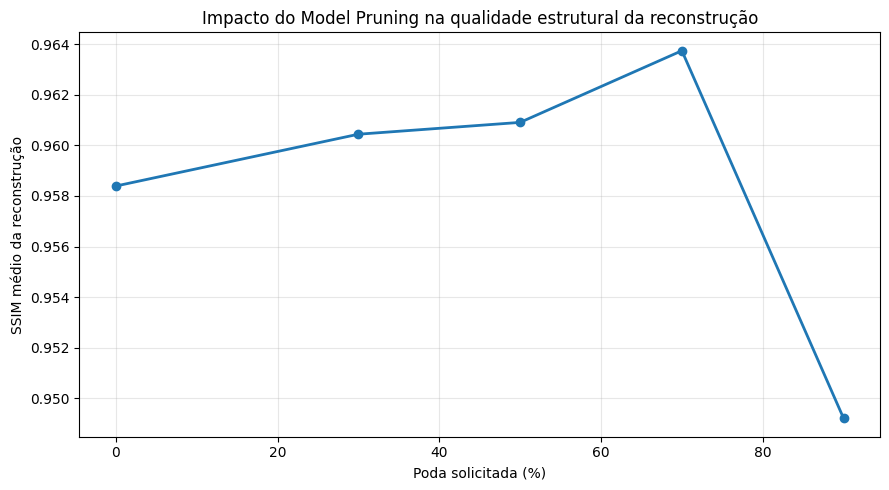

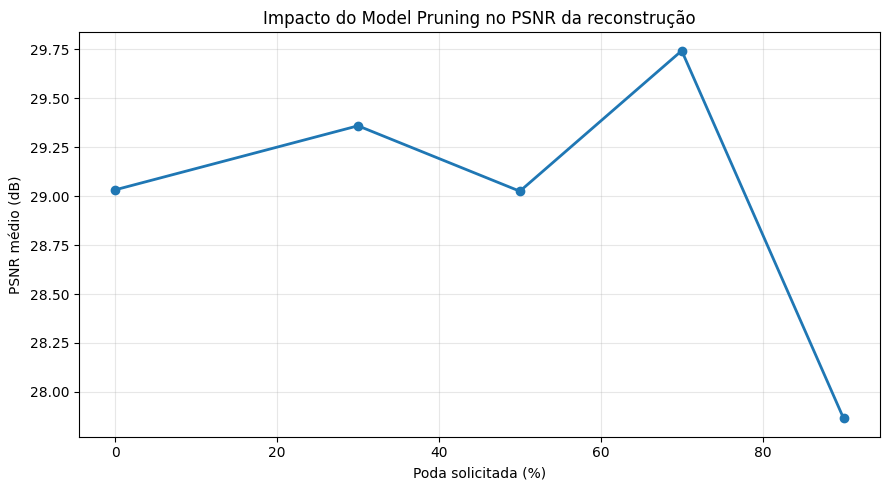

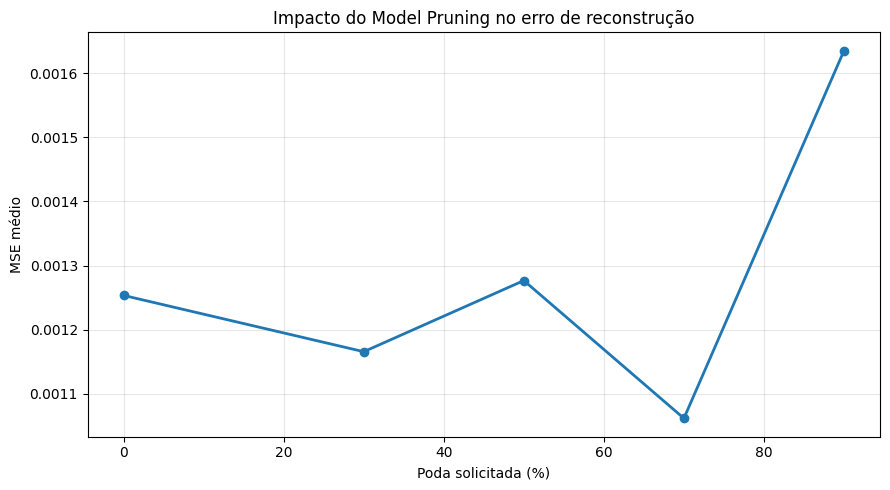

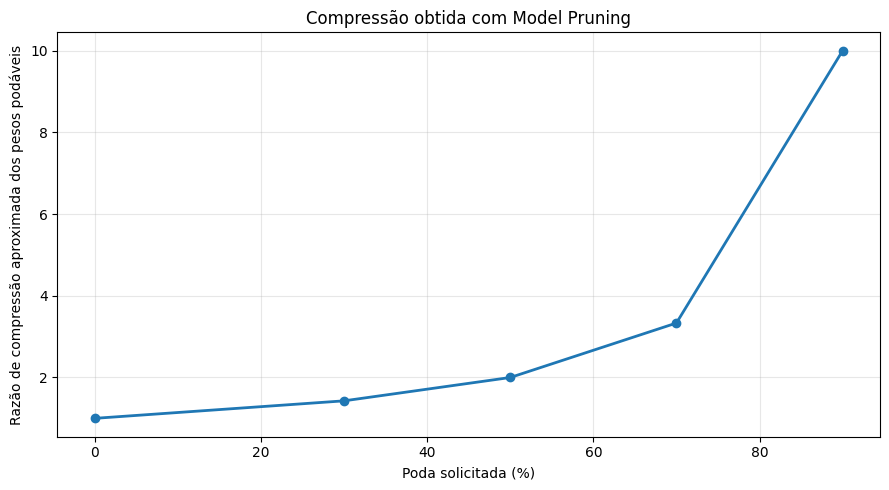

In [ ]:
# ============ GRÁFICOS: IMPACTO DA COMPRESSÃO NO ATAQUE ============

summary_pruning = (
    all_pruning_metrics
    .groupby("experimento")
    .agg(
        pruning_amount=("pruning_amount", "first"),
        sparsity_prunable_weights=("sparsity_prunable_weights", "first"),
        compression_ratio=("compression_ratio_prunable_weights", "first"),
        mse_mean=("mse", "mean"),
        mse_std=("mse", "std"),
        psnr_mean=("psnr", "mean"),
        psnr_std=("psnr", "std"),
        ssim_mean=("ssim", "mean"),
        ssim_std=("ssim", "std"),
    )
    .sort_values("pruning_amount")
    .reset_index()
)

display(summary_pruning.round(4))

plt.figure(figsize=(9, 5))
plt.plot(summary_pruning["pruning_amount"] * 100, summary_pruning["ssim_mean"], marker="o", linewidth=2)
plt.xlabel("Poda solicitada (%)")
plt.ylabel("SSIM médio da reconstrução")
plt.title("Impacto do Model Pruning na qualidade estrutural da reconstrução")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(summary_pruning["pruning_amount"] * 100, summary_pruning["psnr_mean"], marker="o", linewidth=2)
plt.xlabel("Poda solicitada (%)")
plt.ylabel("PSNR médio (dB)")
plt.title("Impacto do Model Pruning no PSNR da reconstrução")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(summary_pruning["pruning_amount"] * 100, summary_pruning["mse_mean"], marker="o", linewidth=2)
plt.xlabel("Poda solicitada (%)")
plt.ylabel("MSE médio")
plt.title("Impacto do Model Pruning no erro de reconstrução")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(summary_pruning["pruning_amount"] * 100, summary_pruning["compression_ratio"], marker="o", linewidth=2)
plt.xlabel("Poda solicitada (%)")
plt.ylabel("Razão de compressão aproximada dos pesos podáveis")
plt.title("Compressão obtida com Model Pruning")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visualização das reconstruções por nível de poda

A célula abaixo mostra as reconstruções para cada experimento. Se você testar muitos níveis em `PRUNING_AMOUNTS`, a saída pode ficar grande; nesse caso, edite `AMOUNTS_TO_PLOT` para escolher apenas alguns níveis.

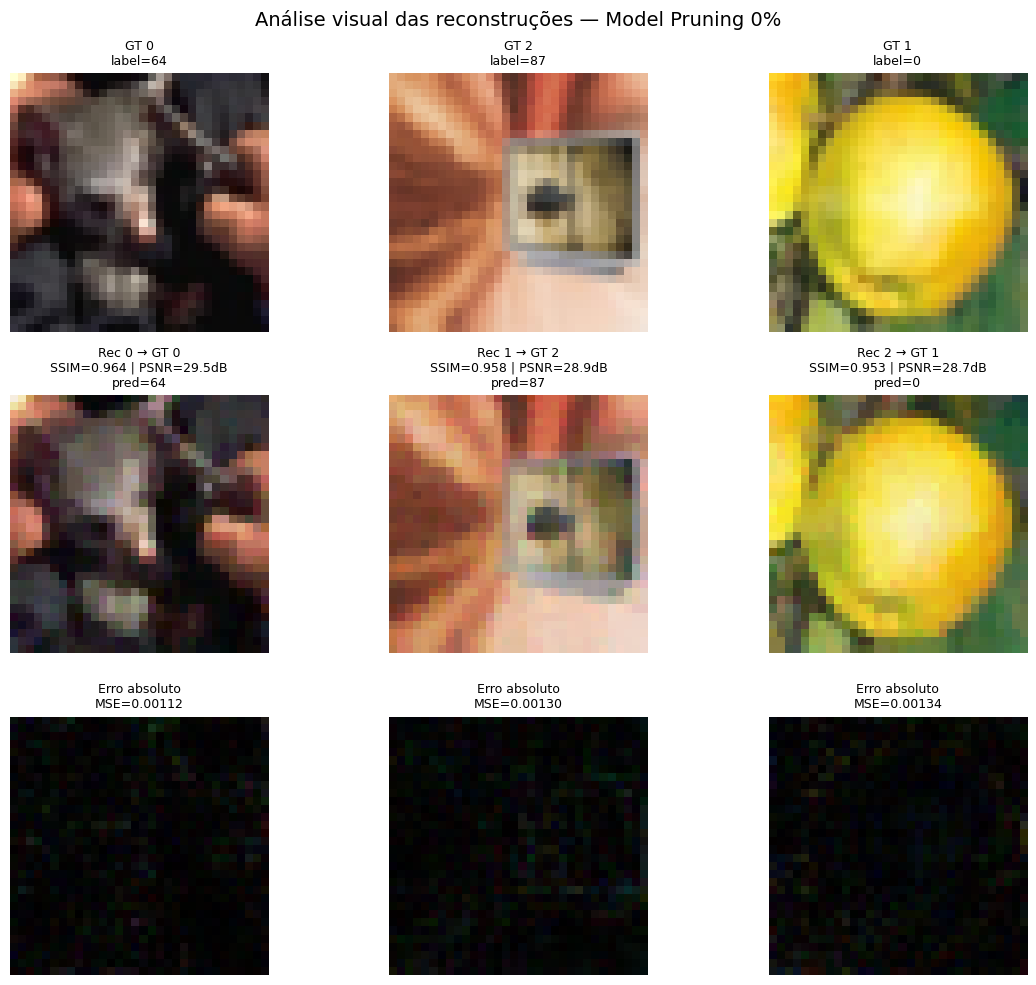

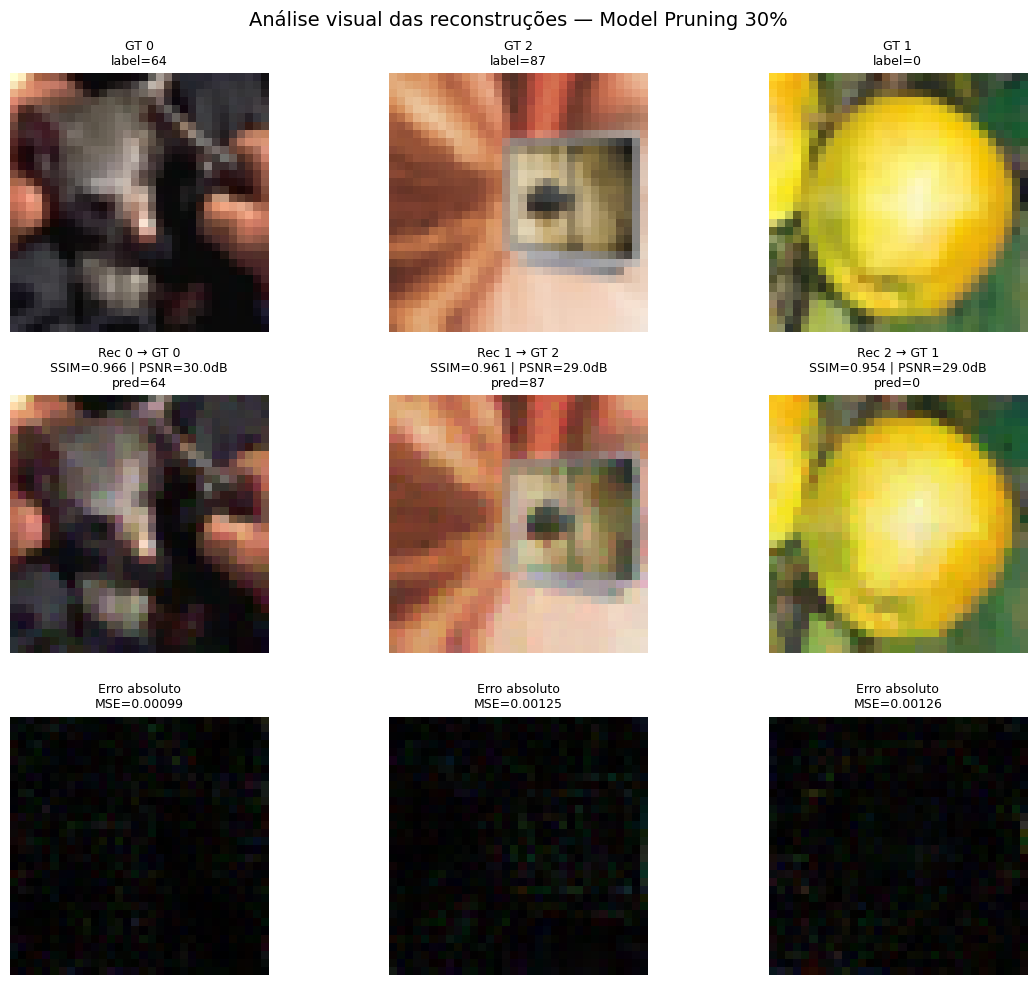

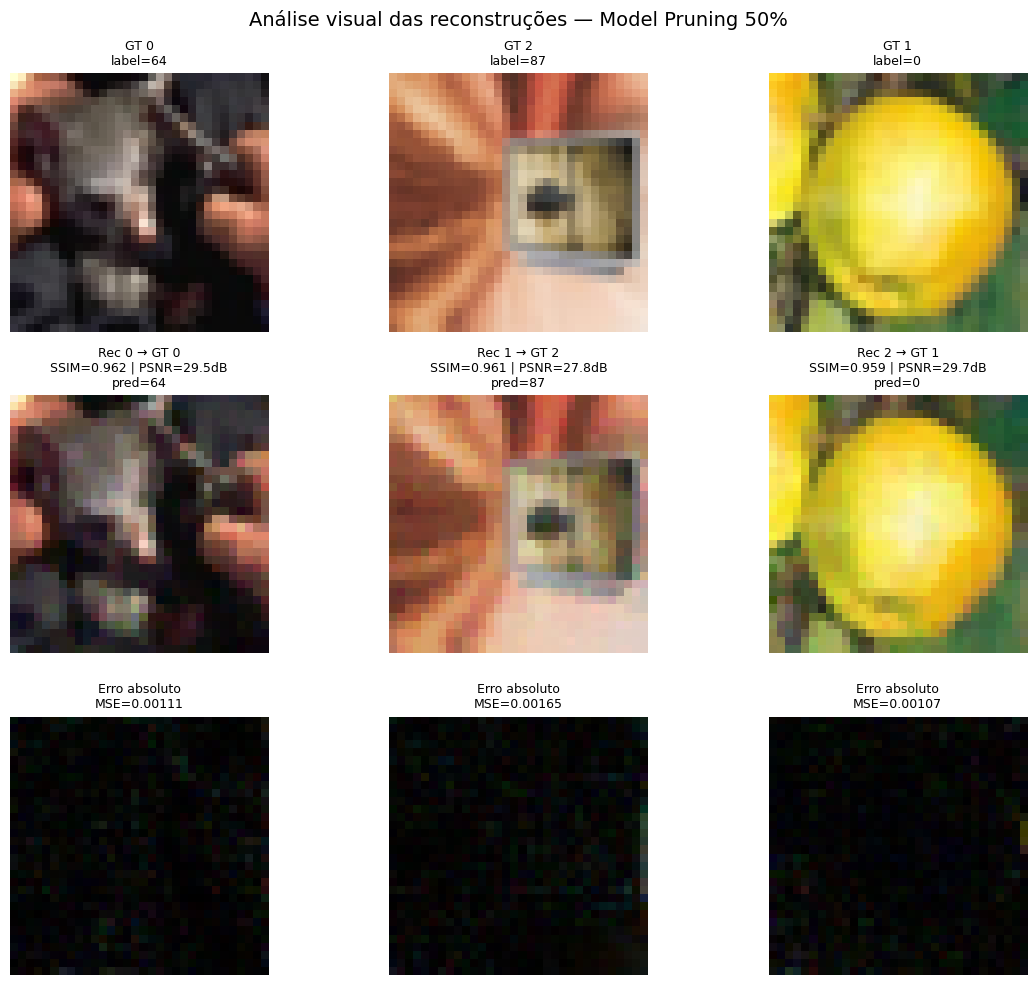

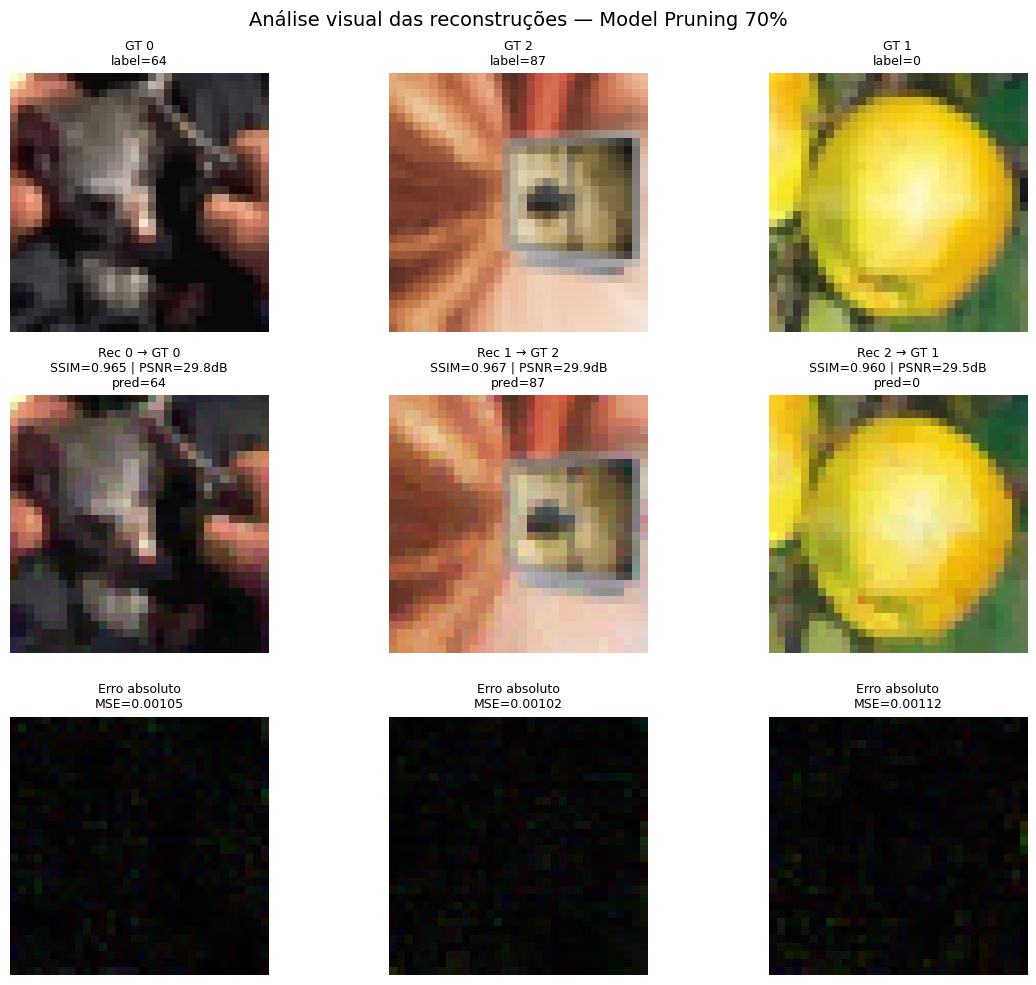

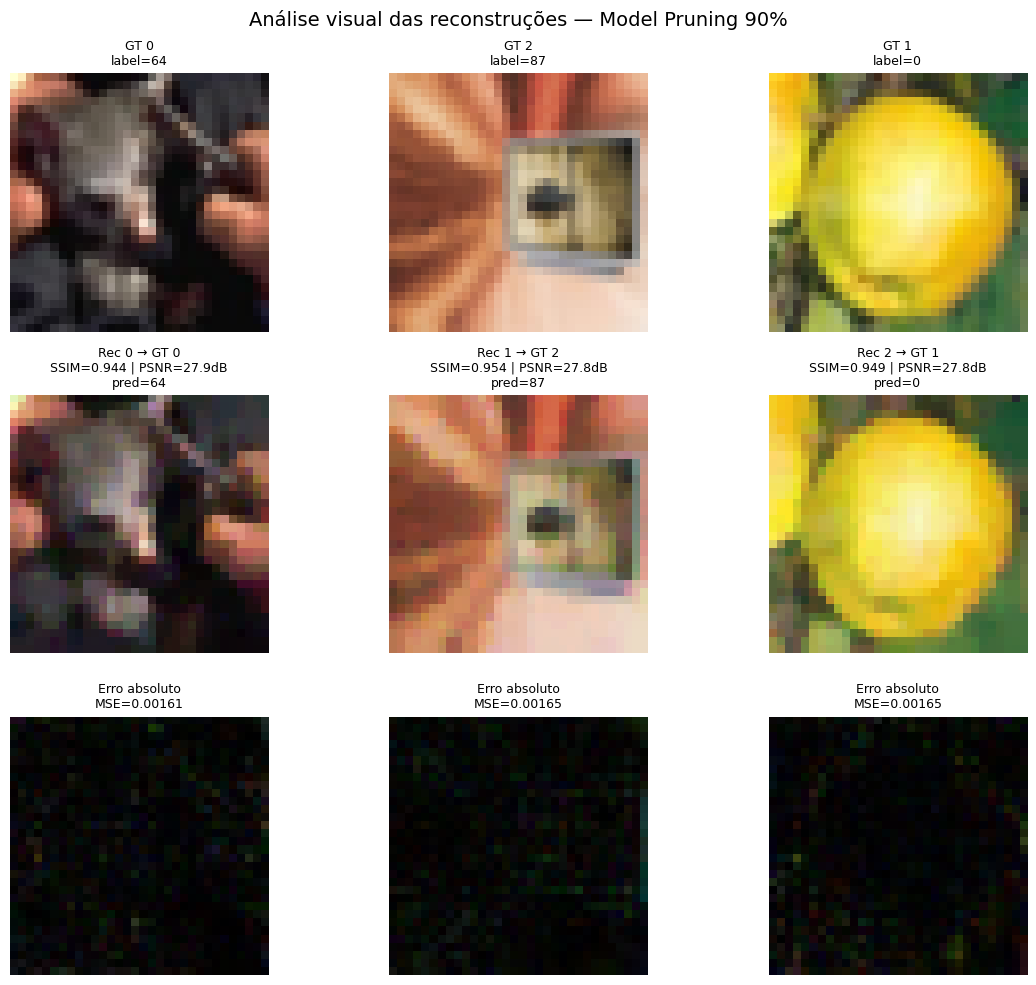

In [ ]:
# ============ VISUALIZAÇÃO POR EXPERIMENTO ============

AMOUNTS_TO_PLOT = PRUNING_AMOUNTS  # Exemplo alternativo: [0.0, 0.5, 0.9]

for result in pruning_results:
    amount = result["pruning_amount"]
    if amount not in AMOUNTS_TO_PLOT:
        continue

    plot_reconstruction_grid(
        reconstructed=result["reconstructed"],
        ground_truth=gt_data,
        labels=gt_label,
        pred_logits=result["dummy_label"],
        name=result["experiment_name"],
    )

In [ ]:
# ============ INTERPRETAÇÃO AUTOMÁTICA DOS RESULTADOS ============

baseline_row = summary_pruning.loc[summary_pruning["pruning_amount"] == 0.0]

if baseline_row.empty:
    print("Nenhum baseline com pruning_amount = 0.0 foi encontrado.")
    print("Inclua 0.0 em PRUNING_AMOUNTS para calcular deltas contra o ataque sem poda.")
else:
    baseline = baseline_row.iloc[0]
    print("\n" + "="*72)
    print("INTERPRETAÇÃO — MODEL PRUNING COMO DEFESA CONTRA DLG")
    print("="*72)

    print("\nBaseline sem poda:")
    print(f"  SSIM médio : {baseline['ssim_mean']:.4f}")
    print(f"  PSNR médio : {baseline['psnr_mean']:.2f} dB")
    print(f"  MSE médio  : {baseline['mse_mean']:.6f}")

    print("\nVariação por nível de poda:")
    for _, row in summary_pruning.iterrows():
        amount = row["pruning_amount"]
        if amount == 0.0:
            continue

        delta_ssim = row["ssim_mean"] - baseline["ssim_mean"]
        delta_psnr = row["psnr_mean"] - baseline["psnr_mean"]
        delta_mse = row["mse_mean"] - baseline["mse_mean"]

        if delta_ssim < -0.05:
            leitura = "reconstrução claramente pior; indício de maior proteção"
        elif delta_ssim < -0.01:
            leitura = "reconstrução um pouco pior; efeito defensivo moderado"
        elif abs(delta_ssim) <= 0.01:
            leitura = "mudança pequena; efeito defensivo fraco ou inconclusivo"
        else:
            leitura = "reconstrução melhorou; esta poda não protegeu neste batch"

        print(
            f"  Poda {amount:.0%}: "
            f"SSIM Δ={delta_ssim:+.4f}, "
            f"PSNR Δ={delta_psnr:+.2f} dB, "
            f"MSE Δ={delta_mse:+.6f}  → {leitura}."
        )

    best_privacy = summary_pruning.sort_values("ssim_mean", ascending=True).iloc[0]
    print("\nMenor SSIM médio observado:")
    print(
        f"  {best_privacy['experimento']} "
        f"com SSIM={best_privacy['ssim_mean']:.4f}, "
        f"PSNR={best_privacy['psnr_mean']:.2f} dB, "
        f"MSE={best_privacy['mse_mean']:.6f}."
    )

    print("\nObservação final:")
    print(
        "  Model Pruning não é uma garantia formal de privacidade. "
        "Ele pode reduzir, preservar ou até aumentar a informação útil presente nos gradientes, "
        "dependendo do nível de poda, da arquitetura, do batch e da inicialização. "
        "Por isso, a conclusão deve ser baseada nas métricas e nas imagens reconstruídas acima."
    )


INTERPRETAÇÃO — MODEL PRUNING COMO DEFESA CONTRA DLG

Baseline sem poda:
  SSIM médio : 0.9584
  PSNR médio : 29.03 dB
  MSE médio  : 0.001253

Variação por nível de poda:
  Poda 30%: SSIM Δ=+0.0020, PSNR Δ=+0.33 dB, MSE Δ=-0.000088  → mudança pequena; efeito defensivo fraco ou inconclusivo.
  Poda 50%: SSIM Δ=+0.0025, PSNR Δ=-0.01 dB, MSE Δ=+0.000023  → mudança pequena; efeito defensivo fraco ou inconclusivo.
  Poda 70%: SSIM Δ=+0.0053, PSNR Δ=+0.71 dB, MSE Δ=-0.000192  → mudança pequena; efeito defensivo fraco ou inconclusivo.
  Poda 90%: SSIM Δ=-0.0092, PSNR Δ=-1.17 dB, MSE Δ=+0.000382  → mudança pequena; efeito defensivo fraco ou inconclusivo.

Menor SSIM médio observado:
  Model Pruning 90% com SSIM=0.9492, PSNR=27.86 dB, MSE=0.001635.

Observação final:
  Model Pruning não é uma garantia formal de privacidade. Ele pode reduzir, preservar ou até aumentar a informação útil presente nos gradientes, dependendo do nível de poda, da arquitetura, do batch e da inicialização. Por isso, 

# Caso 2 — Atacante usa modelo não comprimido, mas cliente usa modelo comprimido

Nesta avaliação, simulamos um cenário em que o cliente aplica **Model Pruning** antes de calcular os gradientes, mas o atacante não sabe disso ou não usa a mesma versão comprimida do modelo.

Assim, temos uma incompatibilidade entre os dois lados:

- **Cliente:** calcula os gradientes usando uma LeNet podada.
- **Atacante:** tenta reconstruir os dados usando uma LeNet original, sem poda.

Esse cenário é diferente do experimento anterior, em que o atacante usava o mesmo modelo podado do cliente. Aqui, o ataque fica em desvantagem porque tenta aproximar gradientes produzidos por um modelo usando outro modelo como referência.

A lógica do DLG não é alterada. O que muda é apenas o modelo usado internamente pelo atacante durante a otimização.

In [ ]:
# ============ CONFIGURAÇÃO: CLIENTE PODADO, ATACANTE NÃO PODADO ============

# Níveis de poda do cliente.
# Você pode mudar esta lista livremente.
MISMATCH_PRUNING_AMOUNTS = [0.30, 0.50, 0.70, 0.90]

# Número de iterações do ataque neste cenário.
# Pode usar PRUNING_NUM_ITERS ou um valor menor para teste rápido.
MISMATCH_NUM_ITERS = PRUNING_NUM_ITERS

# Semente para deixar as inicializações comparáveis.
MISMATCH_EXPERIMENT_SEED = PRUNING_EXPERIMENT_SEED

print("Cenário simulado:")
print("  Cliente  → modelo podado/comprimido")
print("  Atacante → modelo original/não comprimido")
print("Níveis de poda do cliente:", MISMATCH_PRUNING_AMOUNTS)
print("Iterações por ataque:", MISMATCH_NUM_ITERS)

Cenário simulado:
  Cliente  → modelo podado/comprimido
  Atacante → modelo original/não comprimido
Níveis de poda do cliente: [0.3, 0.5, 0.7, 0.9]
Iterações por ataque: 800


In [ ]:
# ============ EXECUÇÃO: CLIENTE PODADO, ATACANTE NÃO PODADO ============

mismatch_results = []
mismatch_metrics = []

for amount in MISMATCH_PRUNING_AMOUNTS:
    experiment_name = f"Mismatch: cliente podado {amount:.0%}, atacante sem poda"

    print("\n" + "=" * 80)
    print(experiment_name)
    print("=" * 80)

    # 1. Modelo do cliente: cópia da LeNet original com pruning aplicado.
    client_model = make_pruned_model_from_base(net, amount)

    # 2. Modelo do atacante: cópia da LeNet original SEM pruning.
    # Este é o ponto central do Caso 2.
    attacker_model = clone_model_for_pruning(net)

    # 3. Gradientes observados pelo atacante.
    # Eles vêm do modelo podado do cliente.
    client_observed_gradients = compute_observed_gradients(
        client_model,
        gt_data,
        gt_onehot_label
    )

    # 4. Estatísticas de compressão do modelo do cliente.
    client_all_stats = parameter_sparsity_stats(
        client_model,
        only_prunable_weights=False
    )

    client_weight_stats = parameter_sparsity_stats(
        client_model,
        only_prunable_weights=True
    )

    print(f"Poda solicitada no cliente: {amount:.0%}")
    print(f"Zeros nos pesos podáveis do cliente: {100 * client_weight_stats['sparsity']:.2f}%")
    print(f"Razão de compressão dos pesos do cliente: {client_weight_stats['compression_ratio']:.4f}x")

    # 5. Ataque DLG.
    # A função do ataque é a mesma.
    # Porém, o modelo usado pelo atacante é o modelo SEM poda.
    result = run_dlg_attack_for_model(
        attack_model=attacker_model,
        target_gradients=client_observed_gradients,
        experiment_name=experiment_name,
        num_iters=MISMATCH_NUM_ITERS,
        seed=MISMATCH_EXPERIMENT_SEED,
        verbose=True,
    )

    # 6. Avaliação da reconstrução.
    metrics = evaluate_reconstruction_set(
        reconstructed=result["reconstructed"],
        ground_truth=gt_data,
        labels=gt_label,
        pred_logits=result["dummy_label"],
        name=experiment_name,
    )

    metrics["pruning_amount_cliente"] = amount
    metrics["sparsity_all_params_cliente"] = client_all_stats["sparsity"]
    metrics["sparsity_prunable_weights_cliente"] = client_weight_stats["sparsity"]
    metrics["compression_ratio_prunable_weights_cliente"] = client_weight_stats["compression_ratio"]
    metrics["cenario"] = "cliente_podado_atacante_sem_poda"

    mismatch_metrics.append(metrics)

    result["pruning_amount_cliente"] = amount
    result["client_model"] = client_model
    result["attacker_model"] = attacker_model
    result["client_stats_all_params"] = client_all_stats
    result["client_stats_prunable_weights"] = client_weight_stats
    result["metrics"] = metrics
    result["scenario"] = "cliente_podado_atacante_sem_poda"

    mismatch_results.append(result)

all_mismatch_metrics = pd.concat(mismatch_metrics, ignore_index=True)

display(all_mismatch_metrics.round(4))
display(summarize_metrics(all_mismatch_metrics))

print("\nExperimentos do Caso 2 concluídos.")


Mismatch: cliente podado 30%, atacante sem poda
Poda solicitada no cliente: 30%
Zeros nos pesos podáveis do cliente: 30.00%
Razão de compressão dos pesos do cliente: 1.4286x

Mismatch: cliente podado 30%, atacante sem poda
Labels analíticos estimados: [0, 64, 87]
Labels reais:                [0, 64, 87]
cycle    0/266  |  loss=2.897904  |  tv_coeff=1.00e-05
cycle   10/266  |  loss=1.478768  |  tv_coeff=9.97e-06
cycle   20/266  |  loss=1.904773  |  tv_coeff=9.86e-06
cycle   30/266  |  loss=4.126326  |  tv_coeff=9.69e-06
cycle   40/266  |  loss=2.783605  |  tv_coeff=9.45e-06
cycle   50/266  |  loss=2.890430  |  tv_coeff=9.16e-06
cycle   60/266  |  loss=2.160685  |  tv_coeff=8.80e-06
cycle   70/266  |  loss=2.343086  |  tv_coeff=8.39e-06
cycle   80/266  |  loss=2.428635  |  tv_coeff=7.94e-06


/usr/local/lib/python3.12/dist-packages/torchvision/transforms/functional.py:282: RuntimeWarning: invalid value encountered in cast
  npimg = (npimg * 255).astype(np.uint8)


cycle   90/266  |  loss=nan  |  tv_coeff=7.44e-06
cycle  100/266  |  loss=nan  |  tv_coeff=6.91e-06
cycle  110/266  |  loss=nan  |  tv_coeff=6.35e-06
cycle  120/266  |  loss=nan  |  tv_coeff=5.78e-06
cycle  130/266  |  loss=nan  |  tv_coeff=5.20e-06
cycle  140/266  |  loss=nan  |  tv_coeff=4.61e-06
cycle  150/266  |  loss=nan  |  tv_coeff=4.03e-06
cycle  160/266  |  loss=nan  |  tv_coeff=3.46e-06
cycle  170/266  |  loss=nan  |  tv_coeff=2.92e-06
cycle  180/266  |  loss=nan  |  tv_coeff=2.41e-06
cycle  190/266  |  loss=nan  |  tv_coeff=1.93e-06
cycle  200/266  |  loss=nan  |  tv_coeff=1.50e-06
cycle  210/266  |  loss=nan  |  tv_coeff=1.12e-06
cycle  220/266  |  loss=nan  |  tv_coeff=7.88e-07
cycle  230/266  |  loss=nan  |  tv_coeff=5.20e-07
cycle  240/266  |  loss=nan  |  tv_coeff=3.16e-07
cycle  250/266  |  loss=nan  |  tv_coeff=1.78e-07
cycle  260/266  |  loss=nan  |  tv_coeff=1.09e-07

Mismatch: cliente podado 50%, atacante sem poda
Poda solicitada no cliente: 50%
Zeros nos pesos pod

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/functional.py:282: RuntimeWarning: invalid value encountered in cast
  npimg = (npimg * 255).astype(np.uint8)


cycle   30/266  |  loss=nan  |  tv_coeff=9.69e-06
cycle   40/266  |  loss=nan  |  tv_coeff=9.45e-06
cycle   50/266  |  loss=nan  |  tv_coeff=9.16e-06
cycle   60/266  |  loss=nan  |  tv_coeff=8.80e-06
cycle   70/266  |  loss=nan  |  tv_coeff=8.39e-06
cycle   80/266  |  loss=nan  |  tv_coeff=7.94e-06
cycle   90/266  |  loss=nan  |  tv_coeff=7.44e-06
cycle  100/266  |  loss=nan  |  tv_coeff=6.91e-06
cycle  110/266  |  loss=nan  |  tv_coeff=6.35e-06
cycle  120/266  |  loss=nan  |  tv_coeff=5.78e-06
cycle  130/266  |  loss=nan  |  tv_coeff=5.20e-06
cycle  140/266  |  loss=nan  |  tv_coeff=4.61e-06
cycle  150/266  |  loss=nan  |  tv_coeff=4.03e-06
cycle  160/266  |  loss=nan  |  tv_coeff=3.46e-06
cycle  170/266  |  loss=nan  |  tv_coeff=2.92e-06
cycle  180/266  |  loss=nan  |  tv_coeff=2.41e-06
cycle  190/266  |  loss=nan  |  tv_coeff=1.93e-06
cycle  200/266  |  loss=nan  |  tv_coeff=1.50e-06
cycle  210/266  |  loss=nan  |  tv_coeff=1.12e-06
cycle  220/266  |  loss=nan  |  tv_coeff=7.88e-07


/usr/local/lib/python3.12/dist-packages/torchvision/transforms/functional.py:282: RuntimeWarning: invalid value encountered in cast
  npimg = (npimg * 255).astype(np.uint8)


cycle   20/266  |  loss=nan  |  tv_coeff=9.86e-06
cycle   30/266  |  loss=nan  |  tv_coeff=9.69e-06
cycle   40/266  |  loss=nan  |  tv_coeff=9.45e-06
cycle   50/266  |  loss=nan  |  tv_coeff=9.16e-06
cycle   60/266  |  loss=nan  |  tv_coeff=8.80e-06
cycle   70/266  |  loss=nan  |  tv_coeff=8.39e-06
cycle   80/266  |  loss=nan  |  tv_coeff=7.94e-06
cycle   90/266  |  loss=nan  |  tv_coeff=7.44e-06
cycle  100/266  |  loss=nan  |  tv_coeff=6.91e-06
cycle  110/266  |  loss=nan  |  tv_coeff=6.35e-06
cycle  120/266  |  loss=nan  |  tv_coeff=5.78e-06
cycle  130/266  |  loss=nan  |  tv_coeff=5.20e-06
cycle  140/266  |  loss=nan  |  tv_coeff=4.61e-06
cycle  150/266  |  loss=nan  |  tv_coeff=4.03e-06
cycle  160/266  |  loss=nan  |  tv_coeff=3.46e-06
cycle  170/266  |  loss=nan  |  tv_coeff=2.92e-06
cycle  180/266  |  loss=nan  |  tv_coeff=2.41e-06
cycle  190/266  |  loss=nan  |  tv_coeff=1.93e-06
cycle  200/266  |  loss=nan  |  tv_coeff=1.50e-06
cycle  210/266  |  loss=nan  |  tv_coeff=1.12e-06


,experimento,rec_idx,gt_idx,mse,psnr,ssim,label_real,label_pred,pruning_amount_cliente,sparsity_all_params_cliente,sparsity_prunable_weights_cliente,compression_ratio_prunable_weights_cliente,cenario
0,"Mismatch: cliente podado 30%, atacante sem poda",0,0,0.0925,10.3378,0.0023,64,0,0.3,0.2995,0.3,1.4286,cliente_podado_atacante_sem_poda
1,"Mismatch: cliente podado 30%, atacante sem poda",1,2,0.3378,4.7140,0.0001,87,0,0.3,0.2995,0.3,1.4286,cliente_podado_atacante_sem_poda
2,"Mismatch: cliente podado 30%, atacante sem poda",2,1,0.3645,4.3827,0.0002,0,0,0.3,0.2995,0.3,1.4286,cliente_podado_atacante_sem_poda
3,"Mismatch: cliente podado 50%, atacante sem poda",0,0,0.0925,10.3378,0.0023,64,0,0.5,0.4992,0.5,2.0000,cliente_podado_atacante_sem_poda
4,"Mismatch: cliente podado 50%, atacante sem poda",1,2,0.3378,4.7140,0.0001,87,0,0.5,0.4992,0.5,2.0000,cliente_podado_atacante_sem_poda
5,"Mismatch: cliente podado 50%, atacante sem poda",2,1,0.3645,4.3827,0.0002,0,0,0.5,0.4992,0.5,2.0000,cliente_podado_atacante_sem_poda
6,"Mismatch: cliente podado 70%, atacante sem poda",0,0,0.3257,4.8719,0.0569,64,64,0.7,0.6988,0.7,3.3333,cliente_podado_atacante_sem_poda
7,"Mismatch: cliente podado 70%, atacante sem poda",1,2,0.2713,5.6656,0.1307,87,87,0.7,0.6988,0.7,3.3333,cliente_podado_atacante_sem_poda
8,"Mismatch: cliente podado 70%, atacante sem poda",2,1,0.3204,4.9436,0.0929,0,0,0.7,0.6988,0.7,3.3333,cliente_podado_atacante_sem_poda
9,"Mismatch: cliente podado 90%, atacante sem poda",0,0,0.0925,10.3378,0.0023,64,0,0.9,0.8985,0.9,10.0000,cliente_podado_atacante_sem_poda


mse                  \
                                                   mean     std     min   
experimento                                                               
Mismatch: cliente podado 30%, atacante sem poda  0.2649  0.1499  0.0925   
Mismatch: cliente podado 50%, atacante sem poda  0.2649  0.1499  0.0925   
Mismatch: cliente podado 70%, atacante sem poda  0.3058  0.0300  0.2713   
Mismatch: cliente podado 90%, atacante sem poda  0.2649  0.1499  0.0925   

                                                           psnr          \
                                                    max    mean     std   
experimento                                                               
Mismatch: cliente podado 30%, atacante sem poda  0.3645  6.4782  3.3466   
Mismatch: cliente podado 50%, atacante sem poda  0.3645  6.4782  3.3466   
Mismatch: cliente podado 70%, atacante sem poda  0.3257  5.1604  0.4391   
Mismatch: cliente podado 90%, atacante sem poda  0.3645  6.4782  3.3466   

                                                                    ssim  \
                                                    min      max    mean   
experimento                                                                
Mismatch: cliente podado 30%, atacante sem poda  4.3827  10.3378  0.0009   
Mismatch: cliente podado 50%, atacante sem poda  4.3827  10.3378  0.0009   
Mismatch: cliente podado 70%, atacante sem poda  4.8719   5.6656  0.0935   
Mismatch: cliente podado 90%, atacante sem poda  4.3827  10.3378  0.0009   

                                                                         
                                                    std     min     max  
experimento                                                              
Mismatch: cliente podado 30%, atacante sem poda  0.0013  0.0001  0.0023  
Mismatch: cliente podado 50%, atacante sem poda  0.0013  0.0001  0.0023  
Mismatch: cliente podado 70%, atacante sem poda  0.0369  0.0569  0.1307  
Mismatch: cliente podado 90%, atacante sem poda  0.0013  0.0001  0.0023


Experimentos do Caso 2 concluídos.


In [ ]:
# ============ RESUMO: CLIENTE PODADO, ATACANTE NÃO PODADO ============

summary_mismatch = (
    all_mismatch_metrics
    .groupby("experimento")
    .agg(
        pruning_amount_cliente=("pruning_amount_cliente", "first"),
        sparsity_cliente=("sparsity_prunable_weights_cliente", "first"),
        compression_ratio_cliente=("compression_ratio_prunable_weights_cliente", "first"),
        mse_mean=("mse", "mean"),
        mse_std=("mse", "std"),
        psnr_mean=("psnr", "mean"),
        psnr_std=("psnr", "std"),
        ssim_mean=("ssim", "mean"),
        ssim_std=("ssim", "std"),
    )
    .sort_values("pruning_amount_cliente")
    .reset_index()
)

display(summary_mismatch.round(4))

,experimento,pruning_amount_cliente,sparsity_cliente,compression_ratio_cliente,mse_mean,mse_std,psnr_mean,psnr_std,ssim_mean,ssim_std
0,"Mismatch: cliente podado 30%, atacante sem poda",0.3,0.3,1.4286,0.2649,0.1499,6.4782,3.3466,0.0009,0.0013
1,"Mismatch: cliente podado 50%, atacante sem poda",0.5,0.5,2.0000,0.2649,0.1499,6.4782,3.3466,0.0009,0.0013
2,"Mismatch: cliente podado 70%, atacante sem poda",0.7,0.7,3.3333,0.3058,0.0300,5.1604,0.4391,0.0935,0.0369
3,"Mismatch: cliente podado 90%, atacante sem poda",0.9,0.9,10.0000,0.2649,0.1499,6.4782,3.3466,0.0009,0.0013


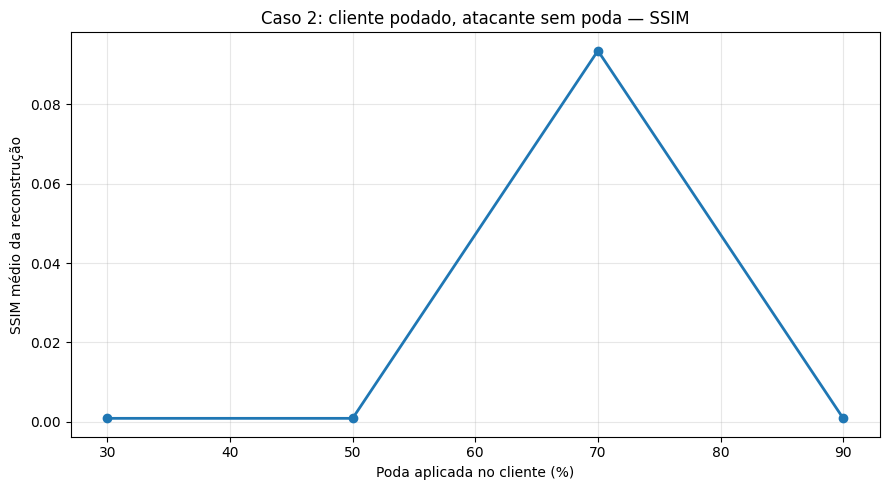

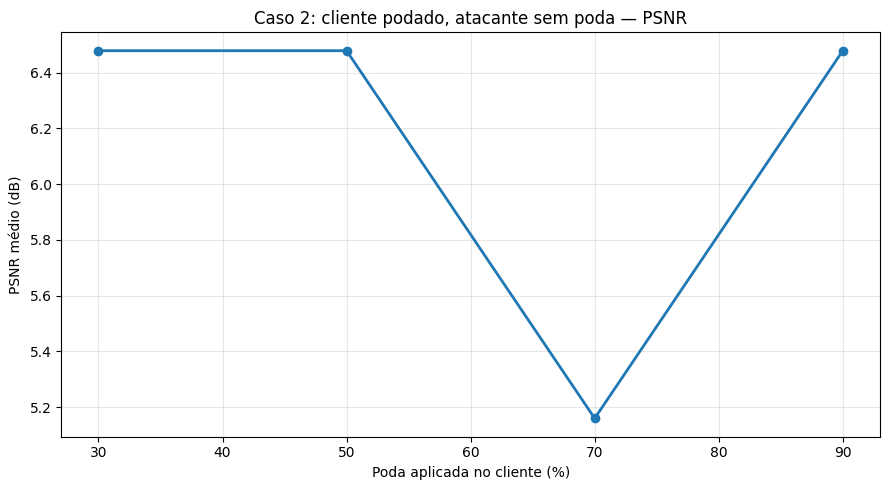

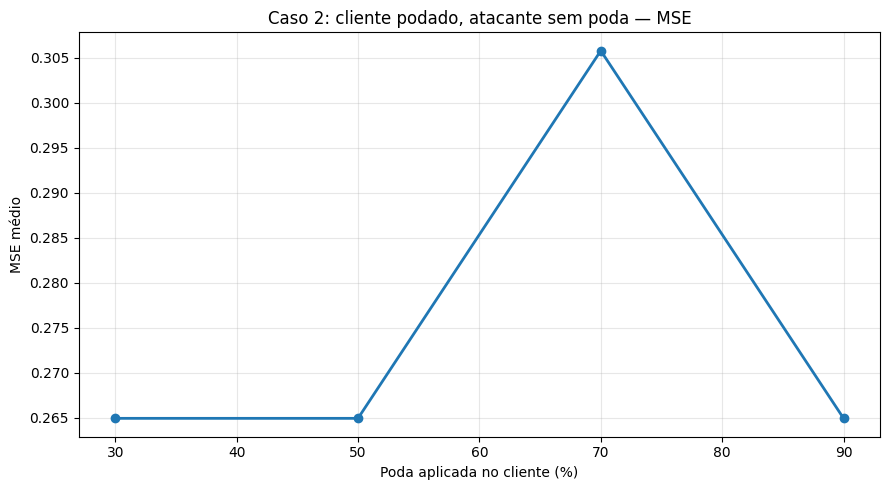

In [ ]:
# ============ GRÁFICOS: IMPACTO DO DESALINHAMENTO ENTRE CLIENTE E ATACANTE ============

plt.figure(figsize=(9, 5))
plt.plot(
    summary_mismatch["pruning_amount_cliente"] * 100,
    summary_mismatch["ssim_mean"],
    marker="o",
    linewidth=2
)
plt.xlabel("Poda aplicada no cliente (%)")
plt.ylabel("SSIM médio da reconstrução")
plt.title("Caso 2: cliente podado, atacante sem poda — SSIM")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    summary_mismatch["pruning_amount_cliente"] * 100,
    summary_mismatch["psnr_mean"],
    marker="o",
    linewidth=2
)
plt.xlabel("Poda aplicada no cliente (%)")
plt.ylabel("PSNR médio (dB)")
plt.title("Caso 2: cliente podado, atacante sem poda — PSNR")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    summary_mismatch["pruning_amount_cliente"] * 100,
    summary_mismatch["mse_mean"],
    marker="o",
    linewidth=2
)
plt.xlabel("Poda aplicada no cliente (%)")
plt.ylabel("MSE médio")
plt.title("Caso 2: cliente podado, atacante sem poda — MSE")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

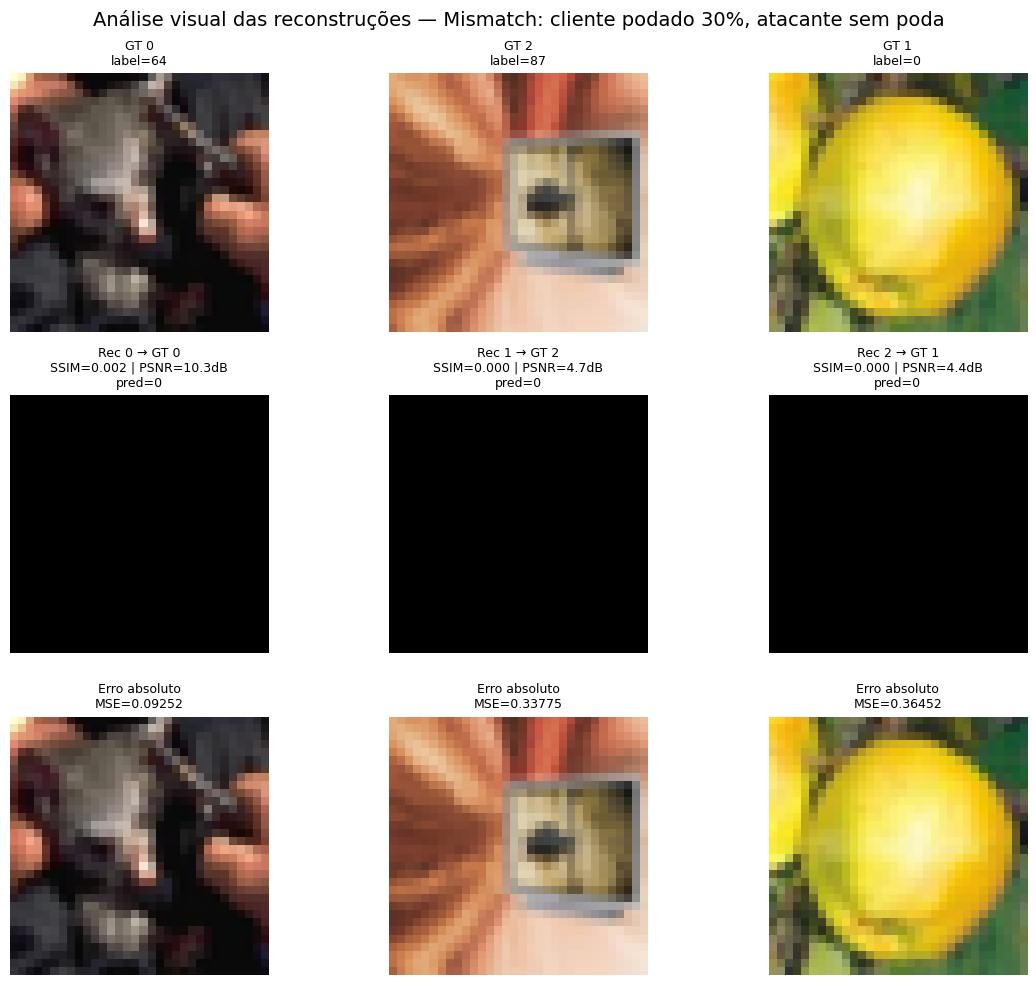

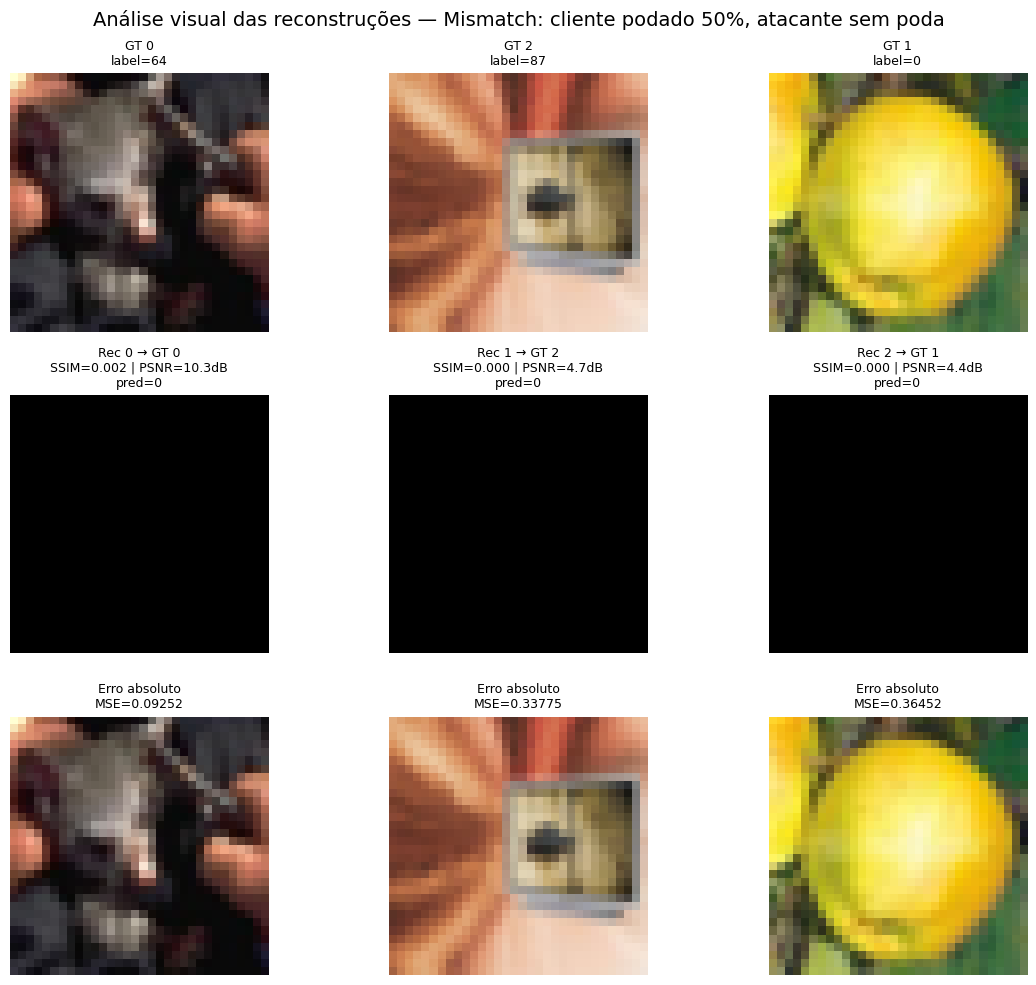

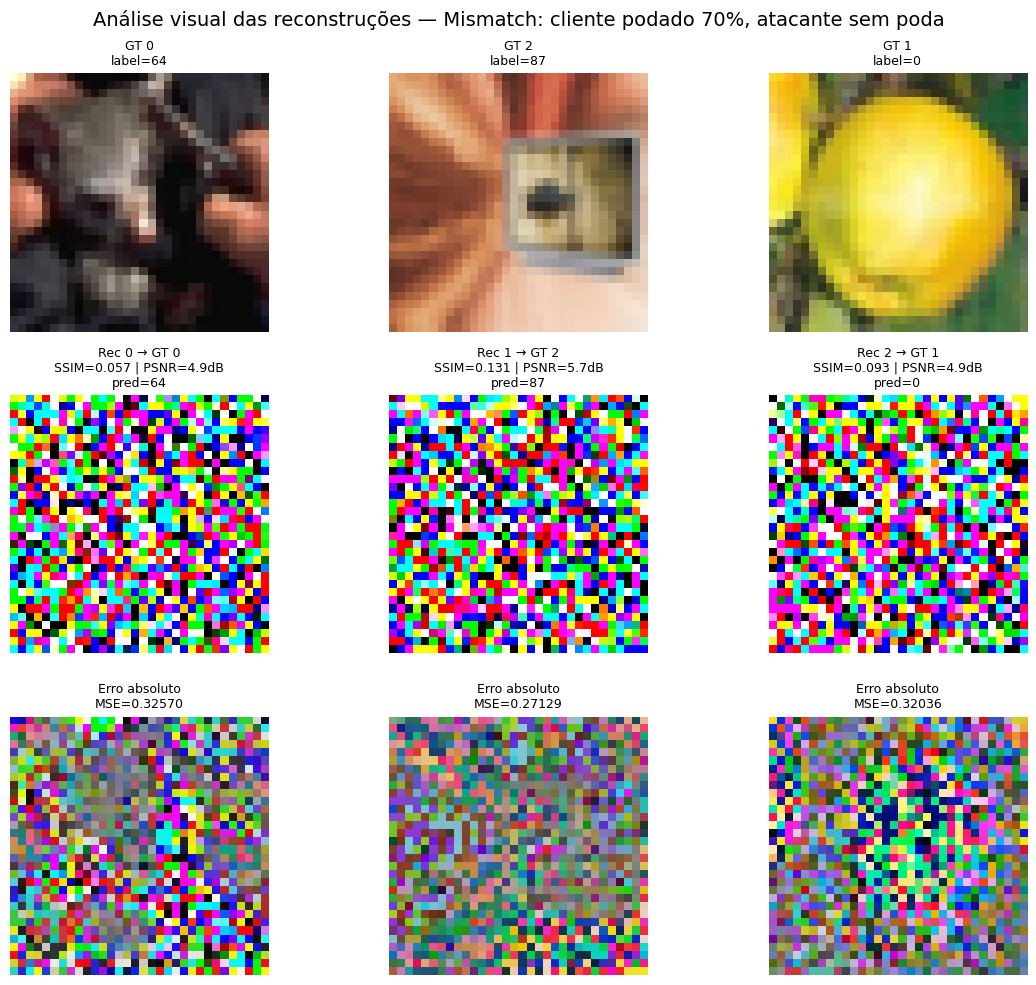

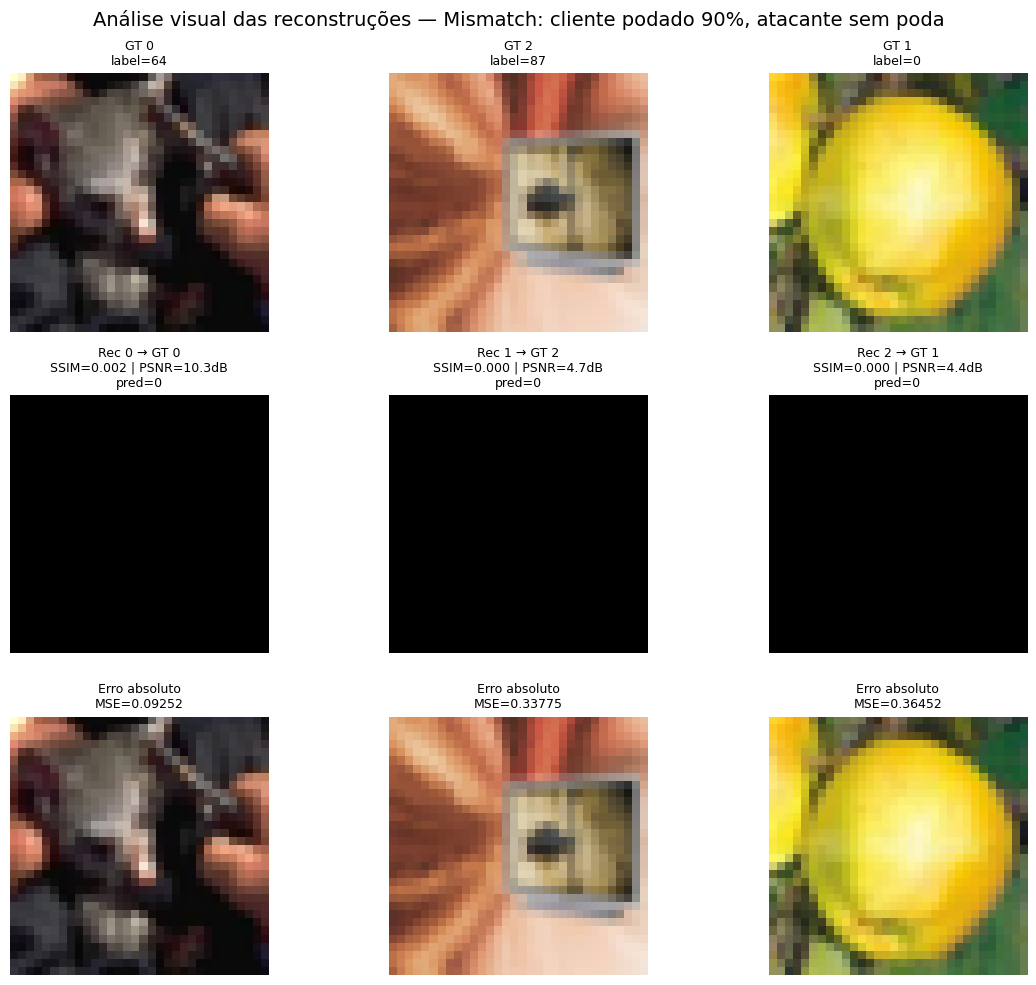

In [ ]:
# ============ VISUALIZAÇÃO DAS RECONSTRUÇÕES DO CASO 2 ============

MISMATCH_AMOUNTS_TO_PLOT = MISMATCH_PRUNING_AMOUNTS

for result in mismatch_results:
    amount = result["pruning_amount_cliente"]

    if amount not in MISMATCH_AMOUNTS_TO_PLOT:
        continue

    plot_reconstruction_grid(
        reconstructed=result["reconstructed"],
        ground_truth=gt_data,
        labels=gt_label,
        pred_logits=result["dummy_label"],
        name=result["experiment_name"],
    )

,poda,ssim_atacante_modelo_correto,psnr_atacante_modelo_correto,mse_atacante_modelo_correto,ssim_atacante_sem_poda,psnr_atacante_sem_poda,mse_atacante_sem_poda,delta_ssim_mismatch_menos_correto,delta_psnr_mismatch_menos_correto,delta_mse_mismatch_menos_correto
0,0.3,0.9604,29.3597,0.0012,0.0009,6.4782,0.2649,-0.9596,-22.8815,0.2638
1,0.5,0.9609,29.0253,0.0013,0.0009,6.4782,0.2649,-0.9600,-22.5472,0.2637
2,0.7,0.9637,29.7435,0.0011,0.0935,5.1604,0.3058,-0.8702,-24.5831,0.3047
3,0.9,0.9492,27.8645,0.0016,0.0009,6.4782,0.2649,-0.9483,-21.3863,0.2633


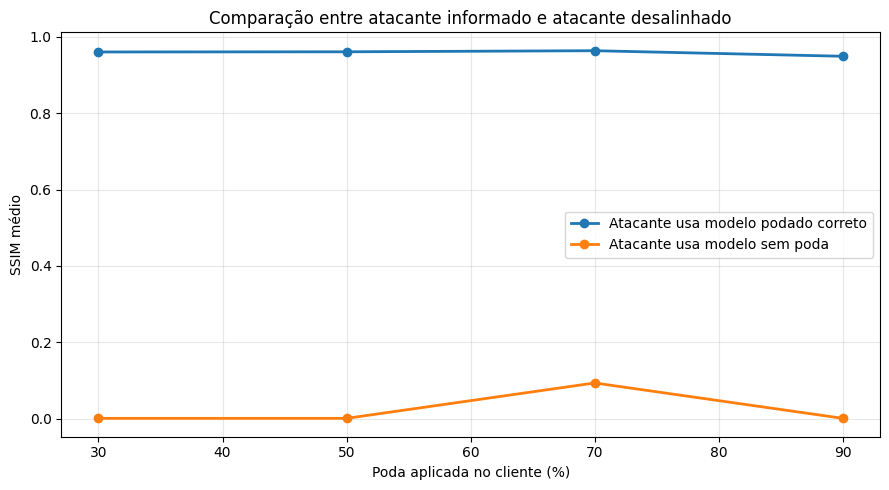

In [ ]:
# ============ COMPARAÇÃO: ATACANTE COM MODELO CORRETO VS ATACANTE COM MODELO ERRADO ============

if "summary_pruning" not in globals():
    print("summary_pruning não encontrado.")
    print("Rode primeiro o experimento anterior, em que o atacante usa o mesmo modelo podado do cliente.")
else:
    fair_summary = summary_pruning.copy()
    fair_summary = fair_summary.rename(columns={
        "pruning_amount": "poda",
        "ssim_mean": "ssim_atacante_modelo_correto",
        "psnr_mean": "psnr_atacante_modelo_correto",
        "mse_mean": "mse_atacante_modelo_correto",
    })

    mismatch_summary = summary_mismatch.copy()
    mismatch_summary = mismatch_summary.rename(columns={
        "pruning_amount_cliente": "poda",
        "ssim_mean": "ssim_atacante_sem_poda",
        "psnr_mean": "psnr_atacante_sem_poda",
        "mse_mean": "mse_atacante_sem_poda",
    })

    comparison_case2 = pd.merge(
        fair_summary[[
            "poda",
            "ssim_atacante_modelo_correto",
            "psnr_atacante_modelo_correto",
            "mse_atacante_modelo_correto",
        ]],
        mismatch_summary[[
            "poda",
            "ssim_atacante_sem_poda",
            "psnr_atacante_sem_poda",
            "mse_atacante_sem_poda",
        ]],
        on="poda",
        how="inner"
    )

    comparison_case2["delta_ssim_mismatch_menos_correto"] = (
        comparison_case2["ssim_atacante_sem_poda"]
        - comparison_case2["ssim_atacante_modelo_correto"]
    )

    comparison_case2["delta_psnr_mismatch_menos_correto"] = (
        comparison_case2["psnr_atacante_sem_poda"]
        - comparison_case2["psnr_atacante_modelo_correto"]
    )

    comparison_case2["delta_mse_mismatch_menos_correto"] = (
        comparison_case2["mse_atacante_sem_poda"]
        - comparison_case2["mse_atacante_modelo_correto"]
    )

    display(comparison_case2.round(4))

    plt.figure(figsize=(9, 5))
    plt.plot(
        comparison_case2["poda"] * 100,
        comparison_case2["ssim_atacante_modelo_correto"],
        marker="o",
        linewidth=2,
        label="Atacante usa modelo podado correto"
    )
    plt.plot(
        comparison_case2["poda"] * 100,
        comparison_case2["ssim_atacante_sem_poda"],
        marker="o",
        linewidth=2,
        label="Atacante usa modelo sem poda"
    )
    plt.xlabel("Poda aplicada no cliente (%)")
    plt.ylabel("SSIM médio")
    plt.title("Comparação entre atacante informado e atacante desalinhado")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()